# Telecom Customer Churn: from raw CSVs to a retention decision

**An end-to-end data analyst / data scientist portfolio notebook**

*Dataset: [Telecom Customer Churn by Maven Analytics](https://www.kaggle.com/datasets/shilongzhuang/telecom-customer-churn-by-maven-analytics) (7,043 California customers, status at the end of Q2 2022, 3 tables).*

**The business question:** *Who is leaving, why, and what is the most profitable way to keep them?*

---

### How this notebook is built

Every section follows the same pattern, so you can learn from it and later reuse it as a template:

> **Skill** – what you practise · **Daily-work use** – where you would use it on the job · **Pitfall** – the mistake it protects you from

| # | Section | Skills practised | Where you use it every week |
|---|---------|------------------|------------------------------|
| 1 | Business framing | Turning a vague request into a target, a metric and a decision | Kick-off meetings, scoping |
| 2 | Data loading & data contract | Safe CSV parsing, validated joins, assertion-based checks | Every new data source |
| 3 | Data-quality audit | Structural vs. random nulls, identity checks, outliers, redundancy | Before any dashboard or model |
| 4 | Feature engineering & leakage audit | Reusable cleaning function, leakage review | Any model, any KPI definition |
| 5 | EDA that drives decisions | Rates with confidence intervals, chi-square / Mann-Whitney, effect sizes, FDR, Pareto | Ad-hoc analysis, stakeholder questions |
| 6 | Survival analysis | Kaplan-Meier, log-rank, Cox regression | Subscriptions, retention, ticket resolution times, SLAs |
| 7 | Predictive modelling | Baselines, pipelines, cross-validation, tuning, PR-AUC, lift, calibration | Any supervised problem |
| 8 | Interpretation & fairness slices | Odds ratios, permutation importance, partial dependence, slice evaluation | Explaining a model to non-technical people |
| 9 | Segmentation | K-Means personas, decision-tree risk rules | Marketing and operations playbooks |
| 10 | From model to decision | Expected-value targeting, sensitivity analysis, BI-ready export | Turning a score into money and an action |
| 11 | Executive summary & limitations | Communicating results and their limits | Every deliverable |

**Deliberately left out:** deep learning, SMOTE/oversampling, AutoML, stacking. On a 7k-row tabular problem they rarely beat a tuned gradient-boosting model and they add complexity you then have to defend.

**Requirements:** Python ≥ 3.10, `pandas>=2.0`, `numpy`, `scipy>=1.11`, `scikit-learn>=1.2`, `matplotlib`, `seaborn`, `lifelines`.
Put the three CSV files in a `data/` folder next to this notebook (or run it on Kaggle).

## 1. Business framing

Good analysis starts before the first line of code. Write down what decision the work supports.

| Question | Answer used in this notebook |
|---|---|
| **Decision** | (a) Which customers should get a retention contact? (b) Which structural problems (contracts, products, support) should be fixed? |
| **Population** | All 7,043 customers who were active during the quarter. |
| **Target** | `churn = 1` if `Customer Status == "Churned"` (left during the quarter), else `0` (`Stayed` or `Joined`). |
| **What about `Joined`?** | The tempting move is to drop them ("they are new and had no time to churn"). Section 3.1 shows why that is a trap: it would turn *"tenure ≤ 3 months"* into a perfect churn predictor. They are kept as retained customers. |
| **Business metric** | Net profit of a retention campaign (Section 10). |
| **Model metrics** | PR-AUC and lift in the top 20% (targeting quality), Brier score and calibration (probabilities feed a money calculation). ROC-AUC is reported but not used alone. |
| **Known limitation** | One snapshot, no history before the churn event. We can describe *who churns*, not prove *what causes* it. |

> **Pitfall:** jumping straight to "predict churn" without agreeing on who is in the population, what counts as churn and what action the prediction will trigger.

## 2. Setup, data loading and the data contract

> **Skill:** parse files safely, join tables with *validated* cardinality, and encode your assumptions as assertions.
> **Daily-work use:** every new extract, API dump or warehouse table you receive.
> **Pitfall:** a join that silently duplicates rows (fan-out) or a parser that silently turns text into nulls.

In [1]:
import os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve, silhouette_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)

# Consistent look: one palette, insight-style left-aligned titles
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False})
C_CHURN, C_STAY, C_GREY = "#D1495B", "#2E86AB", "#8D99AE"
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)

# Where are the CSVs? (set CHURN_DATA_DIR to override)
CANDIDATES = [Path(p) for p in [os.environ.get("CHURN_DATA_DIR", "data"), "data", "../data",
                                "../input/telecom-customer-churn-by-maven-analytics"]]
DATA_DIR = next((p for p in CANDIDATES if (p / "telecom_customer_churn.csv").exists()), None)
assert DATA_DIR is not None, "Put the 3 CSV files in a ./data folder next to this notebook."
print("Reading data from:", DATA_DIR)

Reading data from: data


### 2.1 Load the three tables (and avoid a silent parsing trap)

By default `pandas` converts the text `"None"` into a missing value. In this file `Offer = "None"` means *"the customer accepted no marketing offer"*, which is a real, meaningful category. We show the problem, then fix it by telling `pandas` that only an empty string is missing.

In [2]:
path = DATA_DIR / "telecom_customer_churn.csv"

default_parse = pd.read_csv(path)                                       # pandas default behaviour
careful_parse = pd.read_csv(path, keep_default_na=False, na_values=[""])  # only blanks are nulls

print(f"Offer nulls with default parsing : {default_parse['Offer'].isna().sum():,}   <- 'None' silently became NaN")
print(f"Offer nulls with careful parsing : {careful_parse['Offer'].isna().sum():,}")

raw = careful_parse
zip_pop = pd.read_csv(DATA_DIR / "telecom_zipcode_population.csv")
try:
    dictionary = pd.read_csv(DATA_DIR / "telecom_data_dictionary.csv")
except UnicodeDecodeError:                                               # this file is not UTF-8
    dictionary = pd.read_csv(DATA_DIR / "telecom_data_dictionary.csv", encoding="latin1")

print(f"\ncustomers: {raw.shape} | zip population: {zip_pop.shape} | data dictionary: {dictionary.shape}")

Offer nulls with default parsing : 3,877   <- 'None' silently became NaN
Offer nulls with careful parsing : 0

customers: (7043, 38) | zip population: (1671, 2) | data dictionary: (40, 3)


In [3]:
def profile(frame):
    """One-row-per-column profile: the first thing to look at in any new dataset."""
    return pd.DataFrame({"dtype": frame.dtypes.astype(str), "missing": frame.isna().sum(),
                         "missing_%": (frame.isna().mean() * 100).round(1), "unique": frame.nunique(),
                         "example": frame.iloc[0]})

profile(raw)

,dtype,missing,missing_%,unique,example
Customer ID,object,0,0.000,7043,0002-ORFBO
Gender,object,0,0.000,2,Female
Age,int64,0,0.000,62,37
Married,object,0,0.000,2,Yes
Number of Dependents,int64,0,0.000,10,0
City,object,0,0.000,1106,Frazier Park
Zip Code,int64,0,0.000,1626,93225
Latitude,float64,0,0.000,1626,34.828
Longitude,float64,0,0.000,1625,-118.999
Number of Referrals,int64,0,0.000,12,2


### 2.2 Standardise names and join, then assert the data contract

* `snake_case` column names make code shorter and safer than `df["Avg Monthly GB Download"]`.
* `validate="m:1"` makes `pandas` raise an error if the zip table has duplicate zip codes (which would silently multiply customer rows).
* The **data contract** below turns every assumption we rely on into a check that fails loudly if the data changes.

In [4]:
snake = lambda s: re.sub(r"[^0-9a-z]+", "_", s.strip().lower()).strip("_")

customers = raw.copy()
customers.columns = [snake(c) for c in customers.columns]
zip_pop.columns = [snake(c) for c in zip_pop.columns]

df = customers.merge(zip_pop, on="zip_code", how="left", validate="m:1")

NET_COLS = ["internet_type", "avg_monthly_gb_download", "online_security", "online_backup",
            "device_protection_plan", "premium_tech_support", "streaming_tv", "streaming_movies",
            "streaming_music", "unlimited_data"]
PHONE_COLS = ["avg_monthly_long_distance_charges", "multiple_lines"]
is_churned = df.customer_status.eq("Churned")
no_net, no_phone = df.internet_service.eq("No"), df.phone_service.eq("No")

checks = {
    "customer_id is unique": df.customer_id.is_unique,
    "join did not change the row count (no fan-out)": len(df) == len(customers),
    "every zip code found in the population table": df.population.notna().all(),
    "status is Churned / Stayed / Joined": set(df.customer_status) == {"Churned", "Stayed", "Joined"},
    "churn category & reason filled only for churned customers":
        bool((df.churn_category.notna() == is_churned).all() and (df.churn_reason.notna() == is_churned).all()),
    "Joined customers are new (tenure <= 3 months)": df.loc[df.customer_status.eq("Joined"), "tenure_in_months"].max() <= 3,
    "Total Revenue = Charges - Refunds + Extra Data + Long Distance":
        bool(np.allclose(df.total_charges - df.total_refunds + df.total_extra_data_charges
                         + df.total_long_distance_charges, df.total_revenue, atol=0.01)),
    "internet fields are null exactly when Internet Service = No":
        bool((df[NET_COLS].isna().all(axis=1) == no_net).all() and (df[NET_COLS].isna().any(axis=1) == no_net).all()),
    "phone fields are null exactly when Phone Service = No":
        bool((df[PHONE_COLS].isna().all(axis=1) == no_phone).all() and (df[PHONE_COLS].isna().any(axis=1) == no_phone).all()),
}
contract = pd.DataFrame({"check": checks.keys(), "result": ["PASS" if v else "FAIL" for v in checks.values()]})
display(contract)
assert all(checks.values()), "Data contract violated: investigate before continuing."

,check,result
0,customer_id is unique,PASS
1,join did not change the row count (no fan-out),PASS
2,every zip code found in the population table,PASS
3,status is Churned / Stayed / Joined,PASS
4,churn category & reason filled only for churne...,PASS
5,Joined customers are new (tenure <= 3 months),PASS
6,Total Revenue = Charges - Refunds + Extra Data...,PASS
7,internet fields are null exactly when Internet...,PASS
8,phone fields are null exactly when Phone Servi...,PASS


## 3. Data-quality audit

> **Skill:** distinguish *structural* nulls (the field does not apply) from *random* nulls (data was lost), check business identities, and look at outliers before deciding what to do with them.
> **Daily-work use:** the reason a dashboard number gets challenged in a meeting is almost always a data-quality issue nobody looked for.
> **Pitfall:** applying mean/median imputation to a null that actually means "no service".

In [5]:
nulls = df.isna().sum()
nulls = nulls[nulls > 0]
null_report = pd.DataFrame({"null_count": nulls, "share_%": (nulls / len(df) * 100).round(1)})
null_report["meaning (validated in the contract above)"] = [
    "No home phone service" if c in PHONE_COLS else
    "No internet service" if c in NET_COLS else
    "Customer has not churned" for c in null_report.index]
null_report

,null_count,share_%,meaning (validated in the contract above)
avg_monthly_long_distance_charges,682,9.700,No home phone service
multiple_lines,682,9.700,No home phone service
internet_type,1526,21.700,No internet service
avg_monthly_gb_download,1526,21.700,No internet service
online_security,1526,21.700,No internet service
online_backup,1526,21.700,No internet service
device_protection_plan,1526,21.700,No internet service
premium_tech_support,1526,21.700,No internet service
streaming_tv,1526,21.700,No internet service
streaming_movies,1526,21.700,No internet service


**Decision:** every null in this dataset is *structural*. Nothing was lost, so **no statistical imputation is needed**. We make the meaning explicit instead (`"No internet"`, `0 GB`, and so on) in Section 4. Imputing a mean download volume for customers without internet would invent usage that does not exist.

Next: unusual values and redundant columns.

In [6]:
# 1) Negative monthly charges
neg = df[df.monthly_charge < 0]
print(f"Customers with a negative Monthly Charge: {len(neg)} ({len(neg)/len(df):.1%}); "
      f"range {neg.monthly_charge.min():.0f} to {neg.monthly_charge.max():.0f}")
print("Their status mix:", neg.customer_status.value_counts(normalize=True).round(2).to_dict())

# 2) Outlier share per numeric column (Tukey fences). We *look*, then decide.
num_cols = ["age", "number_of_dependents", "number_of_referrals", "tenure_in_months", "avg_monthly_long_distance_charges",
            "avg_monthly_gb_download", "monthly_charge", "total_charges", "total_refunds",
            "total_extra_data_charges", "total_long_distance_charges", "total_revenue"]
def outlier_share(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()
audit = pd.DataFrame({"min": df[num_cols].min(), "median": df[num_cols].median(), "max": df[num_cols].max(),
                      "skew": df[num_cols].skew(), "outlier_%": df[num_cols].apply(outlier_share) * 100})
audit

Customers with a negative Monthly Charge: 120 (1.7%); range -10 to -1
Their status mix: {'Stayed': 0.7, 'Churned': 0.25, 'Joined': 0.05}


,min,median,max,skew,outlier_%
age,19.000,46.000,80.000,0.162,0.000
number_of_dependents,0.000,0.000,9.000,2.110,23.101
number_of_referrals,0.000,0.000,11.000,1.446,9.598
tenure_in_months,1.000,29.000,72.000,0.241,0.000
avg_monthly_long_distance_charges,1.010,25.690,49.990,-0.002,0.000
avg_monthly_gb_download,2.000,21.000,85.000,1.184,9.215
monthly_charge,-10.000,70.050,118.750,-0.275,0.000
total_charges,18.800,"1,394.550","8,684.800",0.964,0.000
total_refunds,0.000,0.000,49.790,4.329,7.454
total_extra_data_charges,0.000,0.000,150.000,4.091,10.337


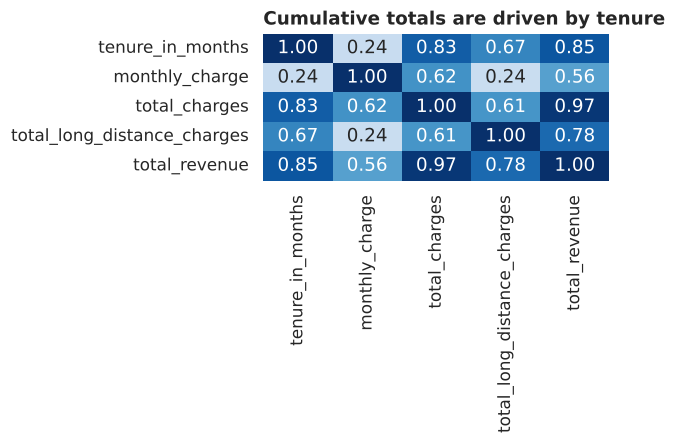

In [7]:
# 3) Redundancy: cumulative totals are mostly "monthly charge x tenure"
cols = ["tenure_in_months", "monthly_charge", "total_charges", "total_long_distance_charges", "total_revenue"]
fig, ax = plt.subplots(figsize=(5.8, 4.2))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title("Cumulative totals are driven by tenure")
plt.tight_layout(); plt.show()

**Findings and decisions**

| Finding | Decision |
|---|---|
| 120 customers have a **negative** monthly charge (credits). They are real billing credits, not typos. | Keep them; floor at 0 when we later estimate customer *value*. |
| Several columns are right-skewed with many "outliers" by the IQR rule (refunds, extra data charges). | **Keep.** They are legitimate business values (most customers have 0). Removing them would delete exactly the customers that are interesting. Tree-based models are insensitive to them. |
| `total_charges`, `total_revenue` and `total_long_distance_charges` are strongly correlated with `tenure_in_months`. | They are *cumulative*, so they mostly re-encode tenure and may have been measured at or after the churn event. Excluded from the production feature set; a **feature-set ablation** in Section 7 shows what this costs (almost nothing). |

> **Pitfall:** deleting outliers by reflex. First ask: *is this value possible in the real world?*

### 3.1 A selection trap: `Status` is partly *defined* by tenure

Before choosing the target, check how `Customer Status` relates to tenure. A common first instinct is to drop `Joined` (new customers) and model `Churned` vs `Stayed`.

In [8]:
early, later = df[df.tenure_in_months <= 3], df[df.tenure_in_months >= 4]
print("Tenure <= 3 months:", early.customer_status.value_counts().to_dict())
print("Tenure >= 4 months:", later.customer_status.value_counts().to_dict())

rate_if_dropped = early[early.customer_status != "Joined"].customer_status.eq("Churned").mean()
rate_if_kept = early.customer_status.eq("Churned").mean()
display(Markdown(f"""
* Every `Stayed` customer has at least 4 months of tenure; customers with up to 3 months are either `Churned` or `Joined`.
* **If `Joined` is dropped**, the early-tenure churn rate becomes **{rate_if_dropped:.0%}** (every remaining customer with up to 3 months churned). A model would learn "tenure of 3 months or less means churn" with certainty, an artifact of how the labels were built, and every early-tenure statistic would be inflated.
* **If `Joined` is kept as retained**, the early-tenure churn rate is **{rate_if_kept:.0%}**: still the riskiest group, but honest.

**Decision:** the target is `Churned` vs everyone else (`Stayed` + `Joined`). This is the kind of problem you only catch by *looking at how the label was constructed*.
"""))

Tenure <= 3 months: {'Churned': 597, 'Joined': 454}
Tenure >= 4 months: {'Stayed': 4720, 'Churned': 1272}



* Every `Stayed` customer has at least 4 months of tenure; customers with up to 3 months are either `Churned` or `Joined`.
* **If `Joined` is dropped**, the early-tenure churn rate becomes **100%** (every remaining customer with up to 3 months churned). A model would learn "tenure of 3 months or less means churn" with certainty, an artifact of how the labels were built, and every early-tenure statistic would be inflated.
* **If `Joined` is kept as retained**, the early-tenure churn rate is **57%**: still the riskiest group, but honest.

**Decision:** the target is `Churned` vs everyone else (`Stayed` + `Joined`). This is the kind of problem you only catch by *looking at how the label was constructed*.


## 4. Feature engineering and the leakage audit

> **Skill:** put all cleaning in **one reusable function** (the same code must run for training and for tomorrow's scoring), and audit every column for **target leakage**.
> **Daily-work use:** the difference between a notebook that only works once and a pipeline you can schedule.
> **Pitfall:** features that contain the answer (or are only known *after* the outcome). They give a beautiful, useless model.

In [9]:
PROTECTION = ["online_security", "online_backup", "device_protection_plan", "premium_tech_support"]
STREAMING = ["streaming_tv", "streaming_movies", "streaming_music"]
YES_NO_FILL = PROTECTION + STREAMING + ["unlimited_data", "multiple_lines"]

def build_features(customers_raw: pd.DataFrame, zip_population: pd.DataFrame) -> pd.DataFrame:
    """Raw customer + zip tables -> clean, model-ready frame. Safe to re-run on new data."""
    d = customers_raw.copy()
    d.columns = [snake(c) for c in d.columns]
    pop = zip_population.copy()
    pop.columns = [snake(c) for c in pop.columns]
    d = d.merge(pop, on="zip_code", how="left", validate="m:1")

    # Structural nulls -> explicit business meaning (validated by the data contract)
    d["offer"] = d["offer"].replace({"None": "No offer"})
    d["internet_type"] = d["internet_type"].fillna("No internet")
    for c in YES_NO_FILL:
        d[c] = d[c].fillna("No")
    d["avg_monthly_gb_download"] = d["avg_monthly_gb_download"].fillna(0)
    d["avg_monthly_long_distance_charges"] = d["avg_monthly_long_distance_charges"].fillna(0)

    # Engineered features
    yes = lambda c: (d[c] == "Yes").astype(int)
    d["n_protection"] = sum(yes(c) for c in PROTECTION)          # security / backup / device / premium support
    d["n_streaming"] = sum(yes(c) for c in STREAMING)
    d["log_population"] = np.log1p(d["population"])               # zip population is very skewed

    # Reporting-only bands (kept out of the model; used for EDA and slice evaluation)
    d["tenure_band"] = pd.cut(d["tenure_in_months"], [0, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
    d["age_band"] = pd.cut(d["age"], [18, 30, 40, 50, 60, 70, 80], labels=["19-30", "31-40", "41-50", "51-60", "61-70", "71-80"])
    d["tech_support_status"] = np.where(d["internet_service"] == "No", "No internet", d["premium_tech_support"])
    d["dependents_band"] = pd.cut(d["number_of_dependents"], [-1, 0, 1, 9], labels=["0", "1", "2+"])
    d["referral_band"] = pd.cut(d["number_of_referrals"], [-1, 0, 1, 4, 11], labels=["0", "1", "2-4", "5+"])

    # Target: Churned = 1; Stayed and Joined = 0 (still a customer at quarter end). See Section 3.1 for why Joined is kept.
    d["churn"] = (d["customer_status"] == "Churned").astype(int)
    return d

df = build_features(raw, pd.read_csv(DATA_DIR / "telecom_zipcode_population.csv"))
assert df.isna().sum()[lambda s: s > 0].index.difference(["churn_category", "churn_reason"]).empty
print("Remaining nulls are only the churn-reason fields (expected).  Shape:", df.shape)

Remaining nulls are only the churn-reason fields (expected).  Shape: (7043, 48)


### 4.1 Leakage audit: which columns may a model see?

For each column ask: *"Would I know this value at the moment I need to make the prediction?"*

In [10]:
print("Churn reason is filled for churned customers only (crosstab below), so a model given it would be 'perfect':")
display(pd.crosstab(df.customer_status, df.churn_reason.notna().rename("has_churn_reason")))

audit = pd.DataFrame([
    ["customer_status, churn_category, churn_reason", "Outcome / post-outcome", "EXCLUDE",
     "Only exist after the customer leaves. Used for descriptive analysis (Section 5), never as inputs."],
    ["customer_id, city, zip_code, latitude, longitude", "Identifiers / high cardinality", "EXCLUDE",
     "1,106 cities and 1,626 zip codes would memorise noise. Zip is used for the population join; geography is explored in EDA."],
    ["population", "Zip-level context", "USE as log_population", "Skewed; the log is more stable. Adds market-density context."],
    ["total_charges, total_revenue, total_long_distance_charges, total_refunds, total_extra_data_charges",
     "Cumulative, tenure-driven", "EXCLUDE", "Redundant with tenure and possibly measured at/after churn. The ablation in Section 7 shows dropping them costs nothing."],
    ["internet_service", "Redundant", "EXCLUDE", "Says exactly what internet_type = 'No internet' says. Duplicated inputs make linear-model coefficients unstable."],
    ["gender", "Protected attribute, no signal", "EXCLUDE from model", "No signal (tested in Section 5.2) and an avoidable fairness risk. Still used to *check* fairness (Section 8)."],
    ["age", "Sensitive attribute, real signal", "USE with care", "Informative, but check policy/legal context before using age to treat customers differently. Ablation in Section 7."],
    ["Joined customers (454 rows)", "New, still active", "KEEP as churn = 0", "Dropping them creates a selection artifact in tenure (Section 3.1). They are censored observations in survival analysis."],
], columns=["column(s)", "role", "decision", "why"])
pd.set_option("display.max_colwidth", 140)
audit

Churn reason is filled for churned customers only (crosstab below), so a model given it would be 'perfect':


has_churn_reason,False,True
customer_status,,
Churned,0,1869
Joined,454,0
Stayed,4720,0


,column(s),role,decision,why
0,"customer_status, churn_category, churn_reason",Outcome / post-outcome,EXCLUDE,"Only exist after the customer leaves. Used for descriptive analysis (Section 5), never as inputs."
1,"customer_id, city, zip_code, latitude, longitude",Identifiers / high cardinality,EXCLUDE,"1,106 cities and 1,626 zip codes would memorise noise. Zip is used for the population join; geography is explored in EDA."
2,population,Zip-level context,USE as log_population,Skewed; the log is more stable. Adds market-density context.
3,"total_charges, total_revenue, total_long_distance_charges, total_refunds, total_extra_data_charges","Cumulative, tenure-driven",EXCLUDE,Redundant with tenure and possibly measured at/after churn. The ablation in Section 7 shows dropping them costs nothing.
4,internet_service,Redundant,EXCLUDE,Says exactly what internet_type = 'No internet' says. Duplicated inputs make linear-model coefficients unstable.
5,gender,"Protected attribute, no signal",EXCLUDE from model,No signal (tested in Section 5.2) and an avoidable fairness risk. Still used to *check* fairness (Section 8).
6,age,"Sensitive attribute, real signal",USE with care,"Informative, but check policy/legal context before using age to treat customers differently. Ablation in Section 7."
7,Joined customers (454 rows),"New, still active",KEEP as churn = 0,Dropping them creates a selection artifact in tenure (Section 3.1). They are censored observations in survival analysis.


In [11]:
TARGET = "churn"
LEAKY = ["customer_status", "churn_category", "churn_reason"]
IDENTIFIERS = ["customer_id", "city", "zip_code", "latitude", "longitude", "population"]
CUMULATIVE = ["total_charges", "total_revenue", "total_long_distance_charges", "total_refunds", "total_extra_data_charges"]
REPORTING = ["tenure_band", "age_band", "dependents_band", "referral_band", "tech_support_status"]
PROTECTED_NO_SIGNAL = ["gender"]
REDUNDANT = ["internet_service"]

FEATURES = [c for c in df.columns
            if c not in [TARGET] + LEAKY + IDENTIFIERS + CUMULATIVE + REPORTING + PROTECTED_NO_SIGNAL + REDUNDANT]
is_num = lambda c: pd.api.types.is_numeric_dtype(df[c])
NUM_FEATURES = [c for c in FEATURES if is_num(c)]
CAT_FEATURES = [c for c in FEATURES if not is_num(c)]

cust = df.copy()                                 # every customer has an outcome: churned (1) or retained (0)

print(f"{len(FEATURES)} model features: {len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical")
print(f"Customers: {len(cust):,} | churned {int(cust[TARGET].sum()):,} ({cust[TARGET].mean():.1%}) | "
      f"retained {int((1 - cust[TARGET]).sum()):,} (of which {int(cust.customer_status.eq('Joined').sum())} are new Joined customers)")
print("\nNumeric    :", NUM_FEATURES)
print("Categorical:", CAT_FEATURES)

26 model features: 10 numeric + 16 categorical
Customers: 7,043 | churned 1,869 (26.5%) | retained 5,174 (of which 454 are new Joined customers)

Numeric    : ['age', 'number_of_dependents', 'number_of_referrals', 'tenure_in_months', 'avg_monthly_long_distance_charges', 'avg_monthly_gb_download', 'monthly_charge', 'n_protection', 'n_streaming', 'log_population']
Categorical: ['married', 'offer', 'phone_service', 'multiple_lines', 'internet_type', 'online_security', 'online_backup', 'device_protection_plan', 'premium_tech_support', 'streaming_tv', 'streaming_movies', 'streaming_music', 'unlimited_data', 'contract', 'paperless_billing', 'payment_method']


## 5. Exploratory analysis that drives decisions

> **Skill:** report rates *with uncertainty*, test differences properly, rank drivers by **effect size** (not p-value), and quantify the business impact.
> **Daily-work use:** the stakeholder question "why is X high?" and the follow-up "so what should we do?".
> **Pitfall:** comparing percentages from groups of very different sizes without a confidence interval, or reporting 30 "significant" p-values when n = 6,589 makes everything significant.

In [12]:
status = df.groupby("customer_status").agg(customers=("customer_id", "size"), avg_tenure_months=("tenure_in_months", "mean"),
                                           avg_monthly_charge=("monthly_charge", "mean"), monthly_revenue=("monthly_charge", "sum"))
status["share_of_customers"] = status.customers / status.customers.sum()
display(status)

base_rate = cust[TARGET].mean()
lost_mrr = cust.loc[cust[TARGET] == 1, "monthly_charge"].sum()
share_mrr = lost_mrr / cust["monthly_charge"].sum()
display(Markdown(f"**Base churn rate = {base_rate:.1%}** of all customers. Churned customers represent "
                 f"**${lost_mrr:,.0f} of monthly recurring revenue ({share_mrr:.1%} of the total)** that has already left."))

,customers,avg_tenure_months,avg_monthly_charge,monthly_revenue,share_of_customers
customer_status,,,,,
Churned,1869,17.979,73.348,"137,086.650",0.265
Joined,454,1.720,42.776,"19,420.300",0.064
Stayed,4720,41.042,61.737,"291,400.600",0.670


**Base churn rate = 26.5%** of all customers. Churned customers represent **$137,087 of monthly recurring revenue (30.6% of the total)** that has already left.

### 5.1 Churn rate by segment, with 95% confidence intervals

The Wilson interval is the right choice for proportions (unlike the textbook normal approximation it behaves well for small groups and rates near 0% or 100%). Red bars are above the overall rate (dashed line).

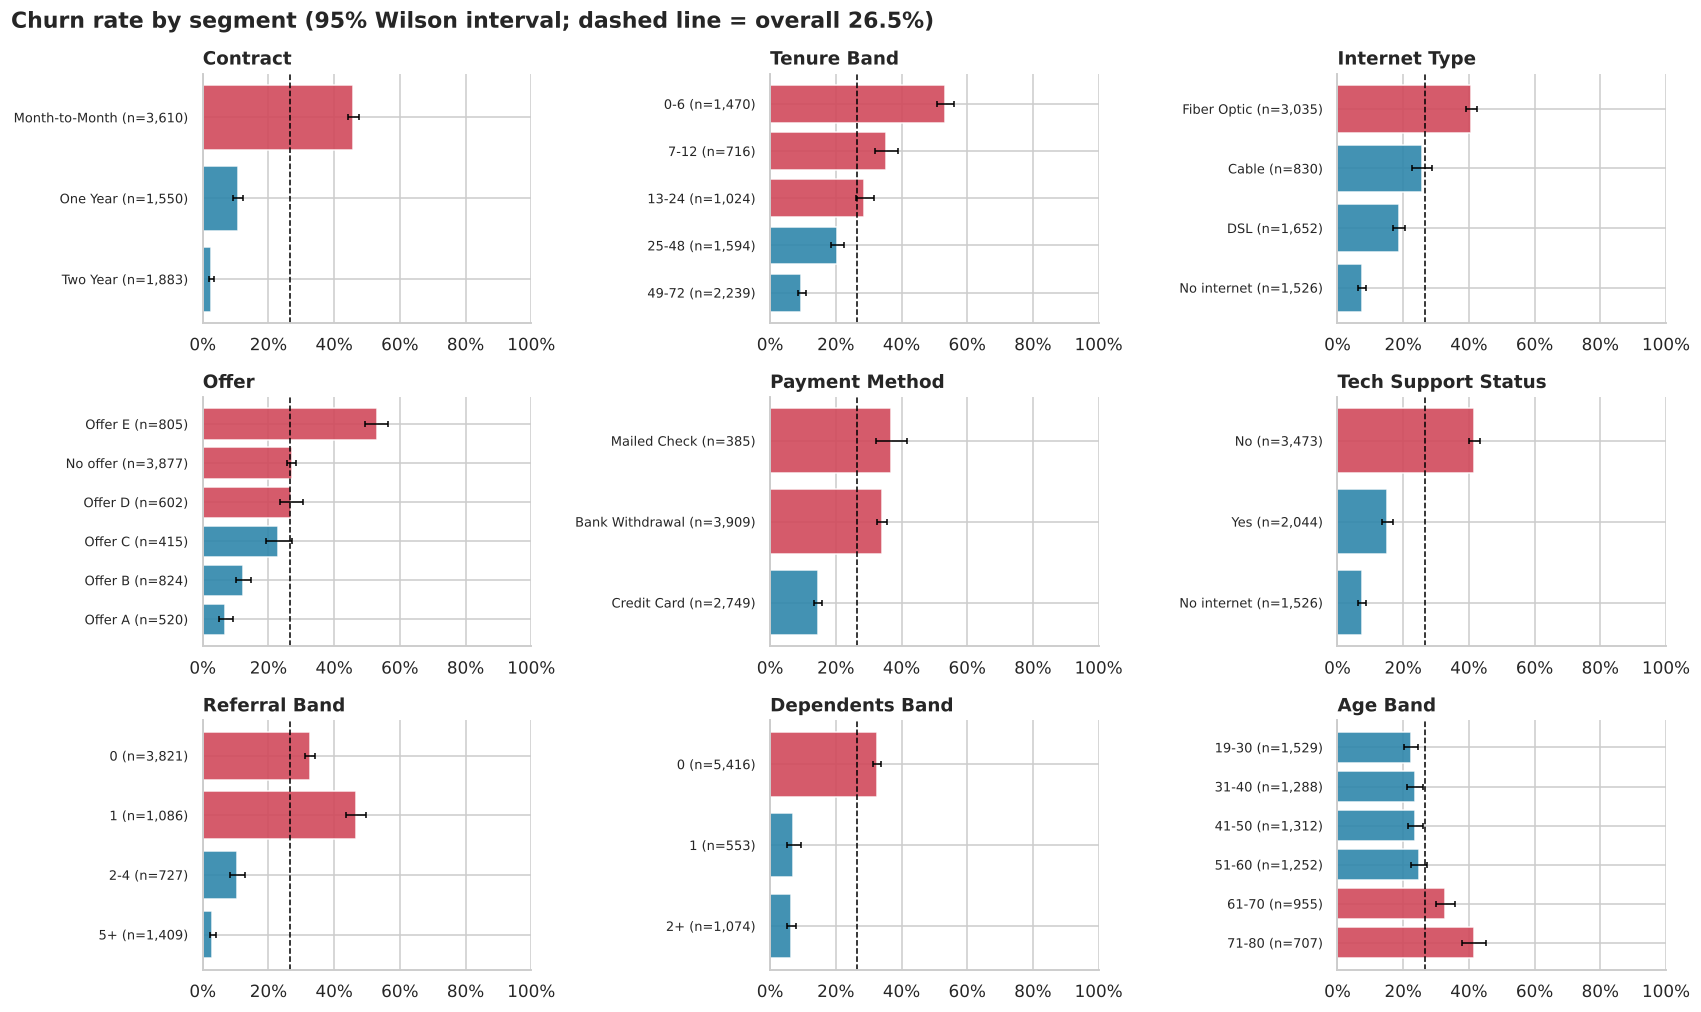

In [13]:
def wilson_ci(k, n, conf=0.95):
    ci = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=conf, method="wilson")
    return ci.low, ci.high

def rate_table(data, col, target=TARGET):
    g = data.groupby(col, observed=True)[target].agg(churners="sum", customers="size").reset_index()
    g["rate"] = g.churners / g.customers
    bounds = [wilson_ci(k, n) for k, n in zip(g.churners, g.customers)]
    g["lo"], g["hi"] = [b[0] for b in bounds], [b[1] for b in bounds]
    return g

def plot_rates(data, cols, ncols=3, base=base_rate):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.0 * nrows))
    axes = np.ravel(axes)
    for ax, col in zip(axes, cols):
        t = rate_table(data, col)
        if not isinstance(data[col].dtype, pd.CategoricalDtype):      # nominal -> sort; ordinal bands keep natural order
            t = t.sort_values("rate", ascending=False)
        y = np.arange(len(t))
        ax.barh(y, t.rate, color=[C_CHURN if r > base else C_STAY for r in t.rate], alpha=0.9)
        ax.errorbar(t.rate, y, xerr=[t.rate - t.lo, t.hi - t.rate], fmt="none", ecolor="black", capsize=2, lw=1)
        ax.set_yticks(y); ax.set_yticklabels([f"{v} (n={n:,})" for v, n in zip(t[col], t.customers)], fontsize=8.5)
        ax.invert_yaxis(); ax.axvline(base, color="black", ls="--", lw=1)
        ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.set_title(col.replace("_", " ").title())
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    return fig

fig = plot_rates(cust, ["contract", "tenure_band", "internet_type", "offer", "payment_method",
                           "tech_support_status", "referral_band", "dependents_band", "age_band"])
fig.suptitle(f"Churn rate by segment (95% Wilson interval; dashed line = overall {base_rate:.1%})", y=1.02, fontweight="bold", x=0.01, ha="left")
plt.show()

In [14]:
r = lambda col, val: cust.loc[cust[col] == val, TARGET].mean()
display(Markdown(f"""
**Reading the chart**

* **Contract is the dominant lever.** Month-to-month customers churn at **{r('contract','Month-to-Month'):.0%}**, one-year at {r('contract','One Year'):.0%}, two-year at {r('contract','Two Year'):.0%}.
* **The first months are the danger zone.** {r('tenure_band','0-6'):.0%} of customers with ≤ 6 months of tenure have churned, versus {r('tenure_band','49-72'):.0%} after four years.
* **Fiber optic** customers churn at {r('internet_type','Fiber Optic'):.0%} versus {r('internet_type','DSL'):.0%} on DSL, and Fiber is also the most expensive product.
* **Offer E** stands out at {r('offer','Offer E'):.0%}; Offers A and B sit at {r('offer','Offer A'):.0%} and {r('offer','Offer B'):.0%}.
* **Premium tech support** (internet customers only): {r('tech_support_status','No'):.0%} churn without it vs {r('tech_support_status','Yes'):.0%} with it.
* Customers with **no referrals or exactly one** churn far more than those who referred 2+ people; customers with **dependents** and with a **credit-card** payment method churn much less.

> **Association is not causation.** Customers who buy tech support, or who accept Offer A, differ from those who do not in many other ways. These charts tell us *where to look and who to target*; they do not prove that selling tech support or Offer A *causes* retention. Proving it requires an A/B test (see Section 11).
"""))


**Reading the chart**

* **Contract is the dominant lever.** Month-to-month customers churn at **46%**, one-year at 11%, two-year at 3%.
* **The first months are the danger zone.** 53% of customers with ≤ 6 months of tenure have churned, versus 10% after four years.
* **Fiber optic** customers churn at 41% versus 19% on DSL, and Fiber is also the most expensive product.
* **Offer E** stands out at 53%; Offers A and B sit at 7% and 12%.
* **Premium tech support** (internet customers only): 42% churn without it vs 15% with it.
* Customers with **no referrals or exactly one** churn far more than those who referred 2+ people; customers with **dependents** and with a **credit-card** payment method churn much less.

> **Association is not causation.** Customers who buy tech support, or who accept Offer A, differ from those who do not in many other ways. These charts tell us *where to look and who to target*; they do not prove that selling tech support or Offer A *causes* retention. Proving it requires an A/B test (see Section 11).


### 5.2 Which drivers matter most? Hypothesis tests plus effect sizes

With 6,589 customers almost any difference is "statistically significant", so **p-values cannot rank drivers**. We use:

* **Chi-square test + Cramér's V** for categorical features (V ≈ 0.1 small, 0.3 medium, 0.5 large)
* **Mann-Whitney U + rank-biserial correlation** for numeric features (non-parametric: no normality assumption on skewed money columns)
* **Benjamini-Hochberg FDR** to correct for running ~35 tests at once (otherwise ~2 would look significant by chance alone at α = 0.05)

We also test `gender` even though it is excluded from the model: a good way to show a *non*-effect.

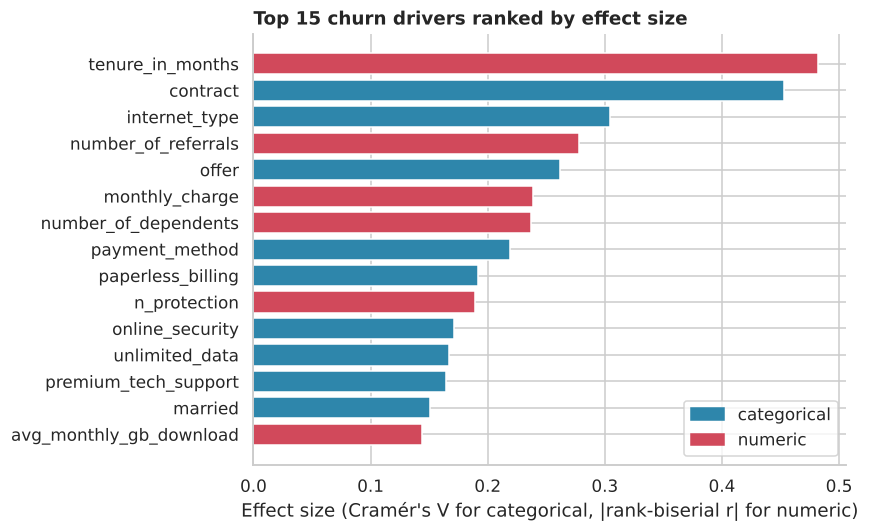

**24 of 27 features are significant after FDR correction**, which is exactly why effect size is what ranks them. `gender` has effect size 0.009 (adjusted p = 0.49): no relationship with churn.

,feature,type,effect_size,p_value,p_adj_BH
0,tenure_in_months,numeric,0.482,0.000,0.000
1,contract,categorical,0.453,0.000,0.000
2,internet_type,categorical,0.305,0.000,0.000
3,number_of_referrals,numeric,0.278,0.000,0.000
4,offer,categorical,0.262,0.000,0.000
5,monthly_charge,numeric,0.239,0.000,0.000
6,number_of_dependents,numeric,0.237,0.000,0.000
7,payment_method,categorical,0.219,0.000,0.000
8,paperless_billing,categorical,0.192,0.000,0.000
9,n_protection,numeric,0.189,0.000,0.000


In [15]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))

rows = []
for c in CAT_FEATURES + ["gender"]:
    ct = pd.crosstab(cust[c], cust[TARGET])
    rows.append((c, "categorical", cramers_v(ct), stats.chi2_contingency(ct)[1]))
for c in NUM_FEATURES:
    a, b = cust.loc[cust[TARGET] == 1, c], cust.loc[cust[TARGET] == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append((c, "numeric", abs(2 * u / (len(a) * len(b)) - 1), p))

effects = pd.DataFrame(rows, columns=["feature", "type", "effect_size", "p_value"])
effects["p_adj_BH"] = stats.false_discovery_control(effects.p_value, method="bh")
effects = effects.sort_values("effect_size", ascending=False).reset_index(drop=True)

top = effects.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.feature, top.effect_size, color=[C_STAY if t == "categorical" else C_CHURN for t in top.type])
ax.set_xlabel("Effect size (Cramér's V for categorical, |rank-biserial r| for numeric)")
ax.set_title("Top 15 churn drivers ranked by effect size")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_STAY), plt.Rectangle((0, 0), 1, 1, color=C_CHURN)],
          labels=["categorical", "numeric"], loc="lower right")
plt.tight_layout(); plt.show()

n_sig = int((effects.p_adj_BH < 0.05).sum())
g = effects.loc[effects.feature == "gender"].iloc[0]
display(Markdown(f"**{n_sig} of {len(effects)} features are significant after FDR correction**, which is exactly why effect size is what ranks them. "
                 f"`gender` has effect size {g.effect_size:.3f} (adjusted p = {g.p_adj_BH:.2f}): no relationship with churn."))
effects.head(10).round(4)

### 5.3 Interaction: contract × internet type

One-dimensional charts hide combinations. A two-way table shows where the real hot-spot is, and it is the first segment a retention team will ask about.

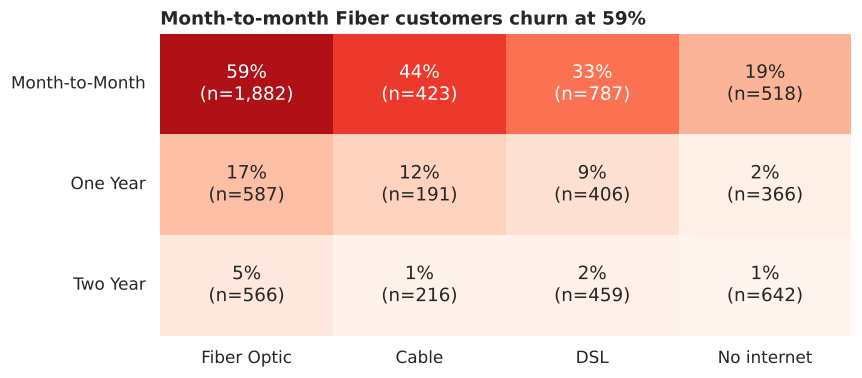

The **month-to-month + Fiber** segment is 27% of customers but contains **59% of all churners**.

In [16]:
order_c = ["Month-to-Month", "One Year", "Two Year"]
order_i = ["Fiber Optic", "Cable", "DSL", "No internet"]
pt = cust.pivot_table(index="contract", columns="internet_type", values=TARGET, aggfunc=["mean", "size"])
rate_m, size_m = pt["mean"].loc[order_c, order_i], pt["size"].loc[order_c, order_i]
annot = np.array([[f"{rate_m.iloc[i, j]:.0%}\n(n={size_m.iloc[i, j]:,})" for j in range(4)] for i in range(3)])

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(rate_m, annot=annot, fmt="", cmap="Reds", vmin=0, vmax=0.7, cbar=False, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
hot = rate_m.loc["Month-to-Month", "Fiber Optic"]
ax.set_title(f"Month-to-month Fiber customers churn at {hot:.0%}")
plt.tight_layout(); plt.show()

n_hot = size_m.loc["Month-to-Month", "Fiber Optic"]
churners_hot = int(round(hot * n_hot))
display(Markdown(f"The **month-to-month + Fiber** segment is {n_hot / len(cust):.0%} of customers but contains "
                 f"**{churners_hot / cust[TARGET].sum():.0%} of all churners**."))

### 5.4 Why do they leave? Pareto of churn reasons, weighted by revenue

Churn reasons are only observable for customers who already left, so they are used **here, for diagnosis, and never as model inputs** (see leakage audit). A Pareto chart shows where the biggest piles are.

,customers,monthly_revenue_lost,avg_tenure,share_of_churners
churn_category,,,,
Competitor,841,"63,742.850",17.749,0.450
Dissatisfaction,321,"23,235.050",18.037,0.172
Attitude,314,"21,894.600",17.338,0.168
Price,211,"14,598.800",19.526,0.113
Other,182,"13,615.350",18.253,0.097


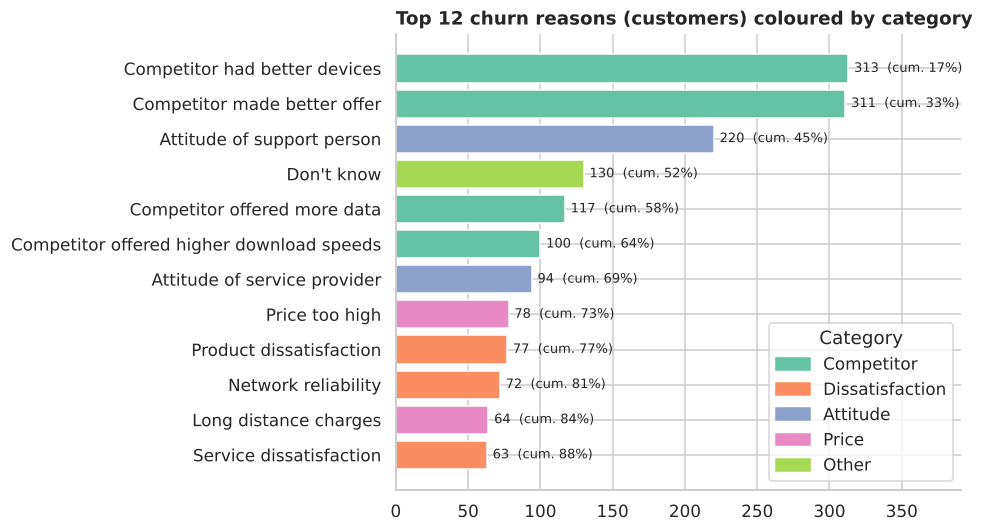

* **Competitors** account for **45% of churners** (better devices, better offers, more data, faster speeds): a product/pricing question.
* **'Attitude of support person'** alone is the #3 reason (220 customers). Together with 'attitude of service provider' this is a **customer-service quality** problem, the cheapest category to fix because it is fully within the company's control.
* Reasons like *Moved* or *Deceased* are not addressable and should be excluded from any 'saveable churn' estimate.

In [17]:
churned = cust[cust[TARGET] == 1]
by_cat = churned.groupby("churn_category").agg(customers=("customer_id", "size"), monthly_revenue_lost=("monthly_charge", "sum"),
                                              avg_tenure=("tenure_in_months", "mean")).sort_values("customers", ascending=False)
by_cat["share_of_churners"] = by_cat.customers / by_cat.customers.sum()
display(by_cat)

reasons = (churned.groupby(["churn_reason", "churn_category"]).agg(customers=("customer_id", "size"),
           monthly_revenue_lost=("monthly_charge", "sum")).reset_index().sort_values("customers", ascending=False))
reasons["cum_share"] = reasons.customers.cumsum() / reasons.customers.sum()
top12 = reasons.head(12)
palette = dict(zip(by_cat.index, sns.color_palette("Set2", len(by_cat))))

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top12))
ax.barh(y, top12.customers, color=[palette[c] for c in top12.churn_category])
ax.set_yticks(y); ax.set_yticklabels(top12.churn_reason); ax.invert_yaxis()
for i, (n, cs) in enumerate(zip(top12.customers, top12.cum_share)):
    ax.text(n + 4, i, f"{n}  (cum. {cs:.0%})", va="center", fontsize=8.5)
ax.set_xlim(0, top12.customers.max() * 1.25)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in palette.values()], labels=list(palette), title="Category", loc="lower right")
ax.set_title("Top 12 churn reasons (customers) coloured by category")
plt.tight_layout(); plt.show()

comp = by_cat.loc["Competitor", "share_of_churners"]
reasons_ranked = reasons.reset_index(drop=True)
support_rank = int(reasons_ranked.index[reasons_ranked.churn_reason.eq("Attitude of support person")][0]) + 1
support = int(reasons_ranked.loc[support_rank - 1, "customers"])
display(Markdown(f"* **Competitors** account for **{comp:.0%} of churners** (better devices, better offers, more data, faster speeds): a product/pricing question.\n"
                 f"* **'Attitude of support person'** alone is the #{support_rank} reason ({support} customers). "
                 f"Together with 'attitude of service provider' this is a **customer-service quality** problem, the cheapest category to fix because it is fully within the company's control.\n"
                 f"* Reasons like *Moved* or *Deceased* are not addressable and should be excluded from any 'saveable churn' estimate."))

### 5.5 Geography: what the zip-code population table adds

The second file only earns its place if it creates something new. Two things it enables: **market penetration** (customers per 1,000 residents) and a **density context** for churn.

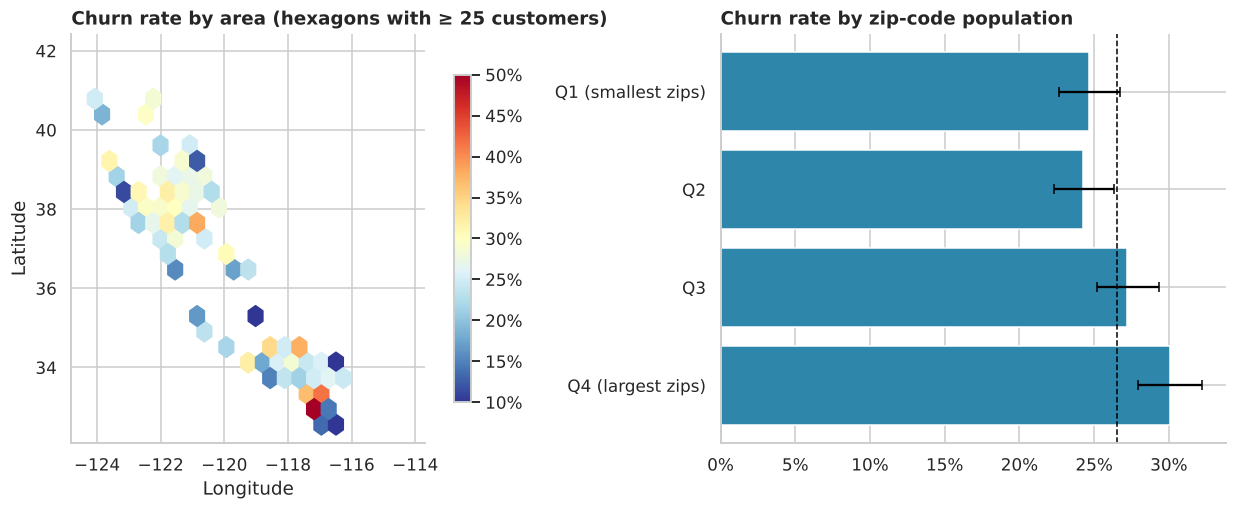

**Top zip codes by market penetration** (population ≥ 5,000 and ≥ 8 customers, to avoid tiny-denominator noise):

,city,customers,population,customers_per_1k_residents
zip_code,,,,
92122,San Diego,36,34902,1.031
92028,Fallbrook,43,42239,1.018
92027,Escondido,38,48690,0.780
92130,San Diego,22,28201,0.780
92117,San Diego,34,51213,0.664
92592,Temecula,30,46171,0.650
92109,San Diego,27,46086,0.586
92126,San Diego,32,74232,0.431


In [18]:
geo = cust.assign(population_quartile=pd.qcut(cust.population, 4, labels=["Q1 (smallest zips)", "Q2", "Q3", "Q4 (largest zips)"]))
t = rate_table(geo, "population_quartile")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
hb = axes[0].hexbin(cust.longitude, cust.latitude, C=cust[TARGET], reduce_C_function=np.mean,
                    gridsize=22, mincnt=25, cmap="RdYlBu_r", vmin=0.1, vmax=0.5)
axes[0].set_aspect(1 / np.cos(np.radians(36.5)))
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude"); axes[0].set_title("Churn rate by area (hexagons with ≥ 25 customers)")
fig.colorbar(hb, ax=axes[0], format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"), shrink=0.8)

y = np.arange(len(t))
axes[1].barh(y, t.rate, color=C_STAY); axes[1].errorbar(t.rate, y, xerr=[t.rate - t.lo, t.hi - t.rate], fmt="none", ecolor="black", capsize=3)
axes[1].set_yticks(y); axes[1].set_yticklabels(t.population_quartile); axes[1].invert_yaxis(); axes[1].axvline(base_rate, ls="--", color="black", lw=1)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[1].set_title("Churn rate by zip-code population")
plt.tight_layout(); plt.show()

zipt = df.groupby("zip_code").agg(city=("city", "first"), customers=("customer_id", "size"), population=("population", "first"))
zipt["customers_per_1k_residents"] = zipt.customers / zipt.population * 1000
display(Markdown("**Top zip codes by market penetration** (population ≥ 5,000 and ≥ 8 customers, to avoid tiny-denominator noise):"))
zipt.query("population >= 5000 and customers >= 8").sort_values("customers_per_1k_residents", ascending=False).head(8)

## 6. Survival analysis: *when* do customers leave?

> **Skill:** Kaplan-Meier curves, the log-rank test and Cox proportional-hazards regression.
> **Daily-work use:** anything with a clock: subscription retention, **ticket resolution time**, time-to-first-response, SLA breaches, time-to-repurchase. Survival methods handle the fact that some cases are not finished yet.
> **Pitfall:** averaging tenure of churned customers only (survivorship bias), or treating "still open" tickets / "still active" customers as if they had finished.

**Setup:** *duration* = `tenure_in_months`; *event* = churned. Customers who stayed or joined are **censored**: we only know they lasted *at least* that long. Handling censoring correctly is the whole point of these methods, and it is why `Joined` customers belong in the analysis.

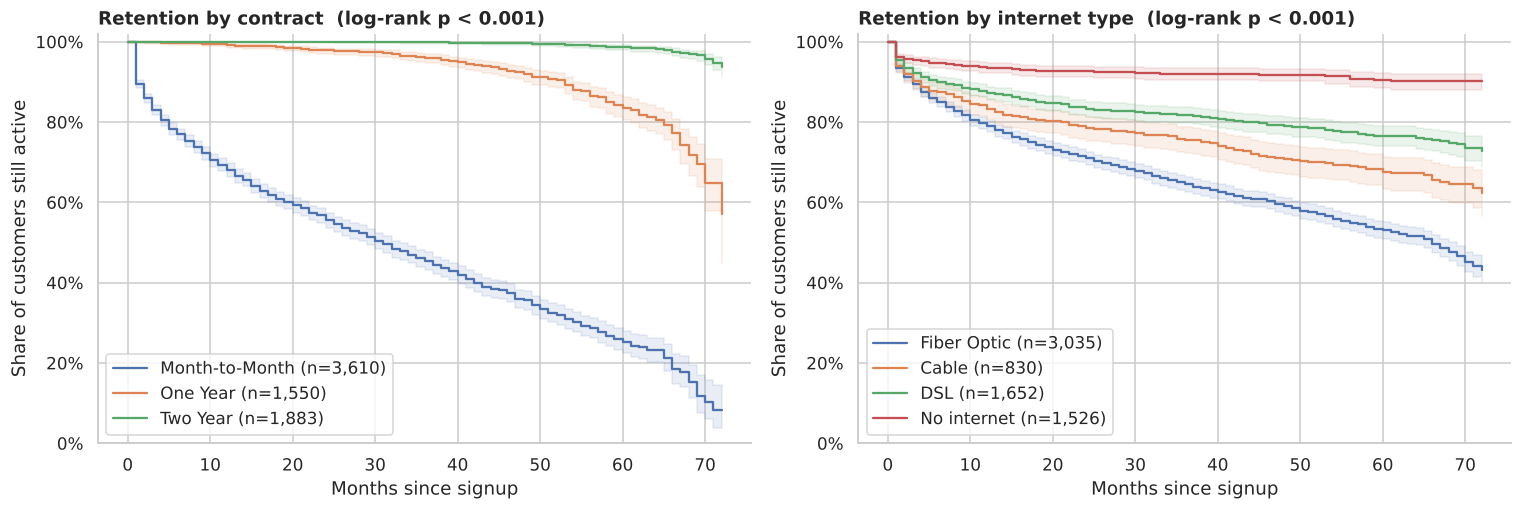

,retained_6m,retained_12m,retained_24m
contract,,,
Month-to-Month,0.770,0.681,0.555
One Year,0.997,0.991,0.979
Two Year,1.000,1.000,1.000


,retained_6m,retained_12m,retained_24m
internet_type,,,
Fiber Optic,0.851,0.789,0.710
Cable,0.876,0.833,0.785
DSL,0.899,0.873,0.832
No internet,0.947,0.935,0.927


In [19]:
surv = df.assign(event=(df.customer_status == "Churned").astype(int), duration=df.tenure_in_months)

def km_panel(ax, col, order):
    kmf = KaplanMeierFitter()
    rows = []
    for name in order:
        g = surv[surv[col] == name]
        kmf.fit(g.duration, g.event, label=f"{name} (n={len(g):,})")
        kmf.plot_survival_function(ax=ax, ci_alpha=0.12)
        s = kmf.survival_function_at_times([6, 12, 24]).values
        rows.append({col: name, "retained_6m": s[0], "retained_12m": s[1], "retained_24m": s[2]})
    ax.set_ylim(0, 1.02); ax.set_xlabel("Months since signup"); ax.set_ylabel("Share of customers still active")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    res = multivariate_logrank_test(surv.duration, surv[col], surv.event)
    ax.set_title(f"Retention by {col.replace('_', ' ')}  (log-rank {'p < 0.001' if res.p_value < 0.001 else f'p = {res.p_value:.3f}'})")
    return pd.DataFrame(rows).set_index(col)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ret_contract = km_panel(axes[0], "contract", ["Month-to-Month", "One Year", "Two Year"])
ret_net = km_panel(axes[1], "internet_type", ["Fiber Optic", "Cable", "DSL", "No internet"])
plt.tight_layout(); plt.show()
display(ret_contract); display(ret_net)

### 6.1 Cox regression: adjusted hazard ratios

Kaplan-Meier compares one factor at a time. The **Cox model** estimates each factor's effect on the churn *hazard* (the instantaneous risk of leaving at a given tenure) **while holding the others constant**. A hazard ratio (HR) of 2 means "twice the risk at any tenure"; HR < 1 means protective. Tenure is the *time axis* here instead of a feature, which is the cleaner way to treat it.

**An assumption check that shapes the model.** Cox assumes each factor multiplies the hazard by a *constant* at every tenure ("proportional hazards"). The curves above show that `contract` does not behave that way: long contracts protect customers early and the risk only appears later. The standard remedy is to **stratify**: every contract type gets its own baseline hazard, and the hazard ratios below are estimated *within* contract types.

Baselines: Cable internet, bank withdrawal, no offer, unmarried.

Earliest churn among two-year contracts: month 25  ->  the contract effect changes over time, so we stratify on it.


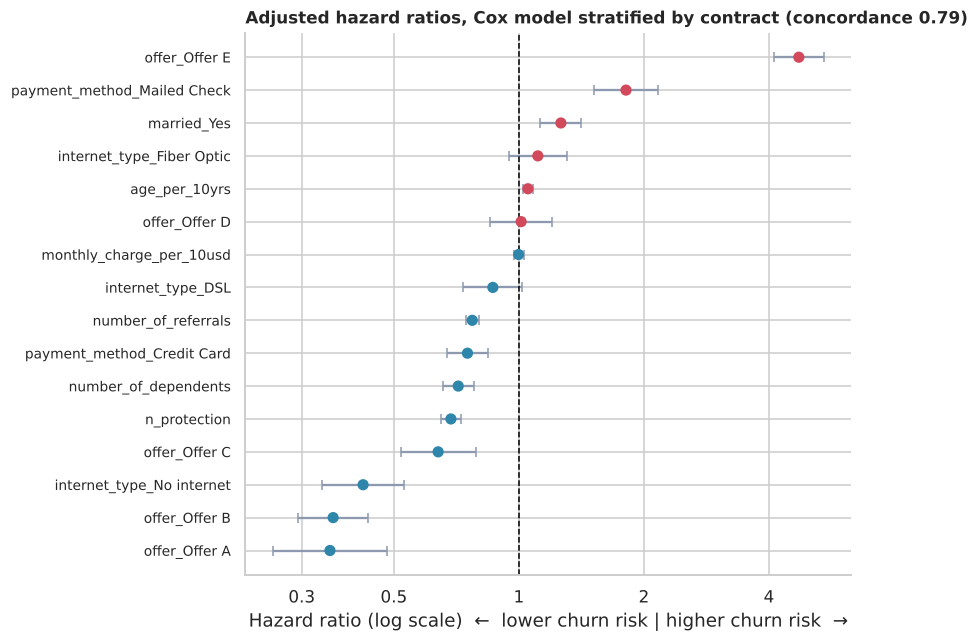

,hazard_ratio,ci_low,ci_high,p
covariate,,,,
offer_Offer E,4.721,4.110,5.424,0.000
payment_method_Mailed Check,1.811,1.516,2.163,0.000
married_Yes,1.262,1.126,1.415,0.000
internet_type_Fiber Optic,1.111,0.945,1.305,0.201
age_per_10yrs,1.052,1.024,1.080,0.000
offer_Offer D,1.012,0.854,1.201,0.887
monthly_charge_per_10usd,0.998,0.971,1.027,0.914
internet_type_DSL,0.866,0.734,1.020,0.085
number_of_referrals,0.772,0.745,0.801,0.000


In [20]:
earliest_2y = int(surv.loc[(surv.contract == "Two Year") & (surv.event == 1), "duration"].min())
print(f"Earliest churn among two-year contracts: month {earliest_2y}  ->  the contract effect changes over time, so we stratify on it.")

cox_src = surv[["contract", "internet_type", "payment_method", "offer", "married", "n_protection", "number_of_referrals",
                "number_of_dependents", "monthly_charge", "age"]].copy()
cox_src["monthly_charge_per_10usd"] = cox_src.pop("monthly_charge") / 10     # rescale so HRs are readable
cox_src["age_per_10yrs"] = cox_src.pop("age") / 10

cox_df = pd.get_dummies(cox_src, columns=["internet_type", "payment_method", "offer", "married"], drop_first=True, dtype=float)
cox_df["duration"], cox_df["event"] = surv.duration.values, surv.event.values

cph = CoxPHFitter(penalizer=0.01).fit(cox_df, duration_col="duration", event_col="event", strata=["contract"])
hr = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].rename(columns={
    "exp(coef)": "hazard_ratio", "exp(coef) lower 95%": "ci_low", "exp(coef) upper 95%": "ci_high"}).sort_values("hazard_ratio")

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(hr))
ax.errorbar(hr.hazard_ratio, y, xerr=[hr.hazard_ratio - hr.ci_low, hr.ci_high - hr.hazard_ratio], fmt="none", ecolor=C_GREY, capsize=3)
ax.scatter(hr.hazard_ratio, y, c=[C_CHURN if h > 1 else C_STAY for h in hr.hazard_ratio], zorder=3, s=40)
ax.axvline(1, ls="--", color="black", lw=1); ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 1, 2, 4]); ax.set_xticklabels(["0.3", "0.5", "1", "2", "4"]); ax.minorticks_off()
ax.set_yticks(y); ax.set_yticklabels(hr.index, fontsize=9)
ax.set_xlabel("Hazard ratio (log scale)  ←  lower churn risk | higher churn risk  →")
ax.set_title(f"Adjusted hazard ratios, Cox model stratified by contract (concordance {cph.concordance_index_:.2f})", fontsize=11)
plt.tight_layout(); plt.show()
hr.round(3).sort_values("hazard_ratio", ascending=False)

In [21]:
sig = hr[hr.p < 0.05]
risk = sig[sig.hazard_ratio > 1].sort_values("hazard_ratio", ascending=False).head(4)
prot = sig[sig.hazard_ratio < 1].sort_values("hazard_ratio").head(5)
married_note = ""
if "married_Yes" in hr.index and hr.loc["married_Yes", "hazard_ratio"] > 1:
    married_note = (f"* **Adjusted can differ from raw.** Married customers churn *less* in the raw data ({r('married','Yes'):.0%} vs {r('married','No'):.0%}) "
                    f"yet show HR {hr.loc['married_Yes', 'hazard_ratio']:.2f} after adjustment, because marriage is entangled with dependents and referrals, which carry the protection.\n")
bullets = lambda t: "\n".join(f"  * `{name}`: HR {row.hazard_ratio:.2f} (95% CI {row.ci_low:.2f} to {row.ci_high:.2f})" for name, row in t.iterrows())
m = ret_contract
display(Markdown(f"""
**Takeaways**

* After 12 months **{m.loc['Month-to-Month','retained_12m']:.0%}** of month-to-month customers remain, against {m.loc['One Year','retained_12m']:.0%} (one-year) and {m.loc['Two Year','retained_12m']:.0%} (two-year). Month-to-month customers keep leaving steadily, so **onboarding and contract conversion in the first months** is where retention is won.
* Strongest **risk** factors after adjustment (significant at 5%):
{bullets(risk)}
* Strongest **protective** factors:
{bullets(prot)}
{married_note}* Hazard ratios are *adjusted*: they show which factors still matter once the others are held fixed. A factor that looked important in the one-at-a-time charts but is not significant here was mostly a proxy for something else.
* Concordance {cph.concordance_index_:.2f}: for a random pair of customers, the model orders who churns first correctly about {cph.concordance_index_:.0%} of the time.

*Extension for production use:* test the proportional-hazards assumption for the remaining covariates (`cph.check_assumptions`) and add time-varying covariates if monthly history is available.
"""))


**Takeaways**

* After 12 months **68%** of month-to-month customers remain, against 99% (one-year) and 100% (two-year). Month-to-month customers keep leaving steadily, so **onboarding and contract conversion in the first months** is where retention is won.
* Strongest **risk** factors after adjustment (significant at 5%):
  * `offer_Offer E`: HR 4.72 (95% CI 4.11 to 5.42)
  * `payment_method_Mailed Check`: HR 1.81 (95% CI 1.52 to 2.16)
  * `married_Yes`: HR 1.26 (95% CI 1.13 to 1.41)
  * `age_per_10yrs`: HR 1.05 (95% CI 1.02 to 1.08)
* Strongest **protective** factors:
  * `offer_Offer A`: HR 0.35 (95% CI 0.26 to 0.48)
  * `offer_Offer B`: HR 0.36 (95% CI 0.29 to 0.43)
  * `internet_type_No internet`: HR 0.42 (95% CI 0.34 to 0.53)
  * `offer_Offer C`: HR 0.64 (95% CI 0.52 to 0.79)
  * `n_protection`: HR 0.69 (95% CI 0.65 to 0.72)
* **Adjusted can differ from raw.** Married customers churn *less* in the raw data (20% vs 33%) yet show HR 1.26 after adjustment, because marriage is entangled with dependents and referrals, which carry the protection.
* Hazard ratios are *adjusted*: they show which factors still matter once the others are held fixed. A factor that looked important in the one-at-a-time charts but is not significant here was mostly a proxy for something else.
* Concordance 0.79: for a random pair of customers, the model orders who churns first correctly about 79% of the time.

*Extension for production use:* test the proportional-hazards assumption for the remaining covariates (`cph.check_assumptions`) and add time-varying covariates if monthly history is available.


## 7. Predictive modelling

> **Skill:** a disciplined supervised-learning workflow: split once, beat simple baselines, use **pipelines** (so preprocessing is learned on training folds only), cross-validate, tune lightly, then evaluate **once** on a held-out test set with the *right* metrics.
> **Daily-work use:** any classification problem (churn, fraud, lead scoring, ticket escalation, no-show).
> **Pitfall:** tuning on the test set, scaling before splitting (leakage), reporting accuracy on an imbalanced target, and skipping the baseline so nobody can tell if the model adds value.

**Algorithms and why only these:** *Logistic regression* (transparent, strong baseline, calibrated) and *gradient boosting* (best default for tabular data; scikit-learn's `HistGradientBoostingClassifier` needs no extra install). Class imbalance here is mild (roughly one churner for every three retained customers), so we use **no resampling**; ranking metrics and calibrated probabilities are enough.

In [22]:
X, y = cust[FEATURES], cust[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"train {X_train.shape[0]:,} rows (churn {y_train.mean():.1%}) | test {X_test.shape[0]:,} rows (churn {y_test.mean():.1%})")

def split_types(cols):
    num = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    return num, [c for c in cols if c not in num]

def make_preprocessor(num, cat, scale):
    """scale=True is the linear-model recipe: standardise numbers and keep ONE column per Yes/No field (a mirrored
    pair would split its weight between two columns). Tree models need neither."""
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                                    drop="if_binary" if scale else None), cat)],
                             verbose_feature_names_out=False)

def make_model(kind, cols):
    """kind: 'prior' (baseline) | 'lr' | 'hgb'. Preprocessing lives inside the pipeline => no leakage in CV."""
    num, cat = split_types(cols)
    if kind == "prior":
        return Pipeline([("model", DummyClassifier(strategy="prior"))])
    if kind == "lr":
        return Pipeline([("prep", make_preprocessor(num, cat, scale=True)), ("model", LogisticRegression(C=0.5, max_iter=3000))])
    if kind == "hgb":
        return Pipeline([("prep", make_preprocessor(num, cat, scale=False)),
                         ("model", HistGradientBoostingClassifier(early_stopping=True, n_iter_no_change=20, max_iter=600, random_state=SEED))])
    raise ValueError(kind)

train 5,634 rows (churn 26.5%) | test 1,409 rows (churn 26.5%)


### 7.1 Tune lightly (training data only)

* **Logistic regression:** the regularisation strength `C` (smaller = simpler model).
* **Gradient boosting:** a *random search* over 4 parameters. Random search beats grid search when only a few parameters matter, and early stopping picks the number of trees automatically.

In [23]:
lr_search = GridSearchCV(make_model("lr", FEATURES), {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
                         scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)
print(f"Logistic regression: best C = {lr_search.best_params_['model__C']}  (CV ROC-AUC {lr_search.best_score_:.4f})")

param_dist = {"model__learning_rate": stats.loguniform(0.02, 0.2), "model__max_leaf_nodes": stats.randint(6, 32),
              "model__min_samples_leaf": stats.randint(10, 100), "model__l2_regularization": stats.loguniform(0.01, 10)}
hgb_search = RandomizedSearchCV(make_model("hgb", FEATURES), param_dist, n_iter=25, scoring="roc_auc",
                                cv=cv, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
print(f"Gradient boosting : CV ROC-AUC {hgb_search.best_score_:.4f}")
print({k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v)) for k, v in hgb_search.best_params_.items()})

models = {"Baseline: churn rate only": make_model("prior", FEATURES),
          "Contract only (logistic)": make_model("lr", ["contract"]),
          "Logistic regression": lr_search.best_estimator_,
          "Gradient boosting (tuned)": hgb_search.best_estimator_}

Logistic regression: best C = 3  (CV ROC-AUC 0.8977)


Gradient boosting : CV ROC-AUC 0.9103
{'l2_regularization': 5.3452, 'learning_rate': 0.0363, 'max_leaf_nodes': 13, 'min_samples_leaf': 13}


### 7.2 Compare against baselines with cross-validation

The *baseline ladder* shows what each added level of complexity buys. If a complex model barely beats "contract type only", the complexity is not worth shipping.

In [24]:
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}
rows = []
for name, mdl in models.items():
    cols = ["contract"] if name.startswith("Contract") else FEATURES
    cvr = cross_validate(clone(mdl), X_train[cols], y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name,
                 "ROC-AUC": f"{cvr['test_roc_auc'].mean():.3f} ± {cvr['test_roc_auc'].std():.3f}",
                 "PR-AUC": f"{cvr['test_pr_auc'].mean():.3f} ± {cvr['test_pr_auc'].std():.3f}",
                 "Brier (lower = better)": f"{-cvr['test_brier'].mean():.3f} ± {cvr['test_brier'].std():.3f}"})
cv_table = pd.DataFrame(rows).set_index("model")
cv_table

,ROC-AUC,PR-AUC,Brier (lower = better)
model,,,
Baseline: churn rate only,0.500 ± 0.000,0.265 ± 0.000,0.195 ± 0.000
Contract only (logistic),0.768 ± 0.013,0.446 ± 0.014,0.155 ± 0.004
Logistic regression,0.898 ± 0.011,0.757 ± 0.025,0.111 ± 0.005
Gradient boosting (tuned),0.910 ± 0.012,0.793 ± 0.028,0.104 ± 0.007


### 7.3 Final evaluation on the untouched test set

Which metrics, and why:

| Metric | Use it for | Why not just accuracy? |
|---|---|---|
| **ROC-AUC** | Overall ranking quality (can the model put churners above stayers?) | Threshold-free |
| **PR-AUC** | Targeting quality when the positive class matters most | More informative than ROC when you care about the churners; the baseline equals the churn rate |
| **Precision / recall / lift @ top 20%** | "If we can only contact 20% of customers, how many churners do we reach?" | Maps directly to campaign capacity |
| **Brier score + calibration curve** | Are the predicted *probabilities* trustworthy? | Needed because Section 10 multiplies probabilities by money |

In [25]:
fitted = {}
for name, mdl in models.items():
    cols = ["contract"] if name.startswith("Contract") else FEATURES
    fitted[name] = (clone(mdl).fit(X_train[cols], y_train), cols)
preds = {name: m.predict_proba(X_test[cols])[:, 1] for name, (m, cols) in fitted.items()}

def top_k(y_true, score, frac=0.20):
    y_true, score = np.asarray(y_true), np.asarray(score)
    idx = np.argsort(-score, kind="stable")[: int(len(score) * frac)]
    precision, capture = y_true[idx].mean(), y_true[idx].sum() / y_true.sum()
    return precision, capture, precision / y_true.mean()

rows = []
for name, p in preds.items():
    prec20, cap20, lift20 = top_k(y_test, p)
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                 "Brier": brier_score_loss(y_test, p), "precision@20%": prec20, "churners captured@20%": cap20, "lift@20%": lift20})
test_table = pd.DataFrame(rows).set_index("model")
test_table

,ROC-AUC,PR-AUC,Brier,precision@20%,churners captured@20%,lift@20%
model,,,,,,
Baseline: churn rate only,0.500,0.265,0.195,0.278,0.209,1.046
Contract only (logistic),0.761,0.438,0.157,0.459,0.345,1.730
Logistic regression,0.891,0.749,0.116,0.751,0.564,2.829
Gradient boosting (tuned),0.904,0.771,0.109,0.783,0.588,2.950


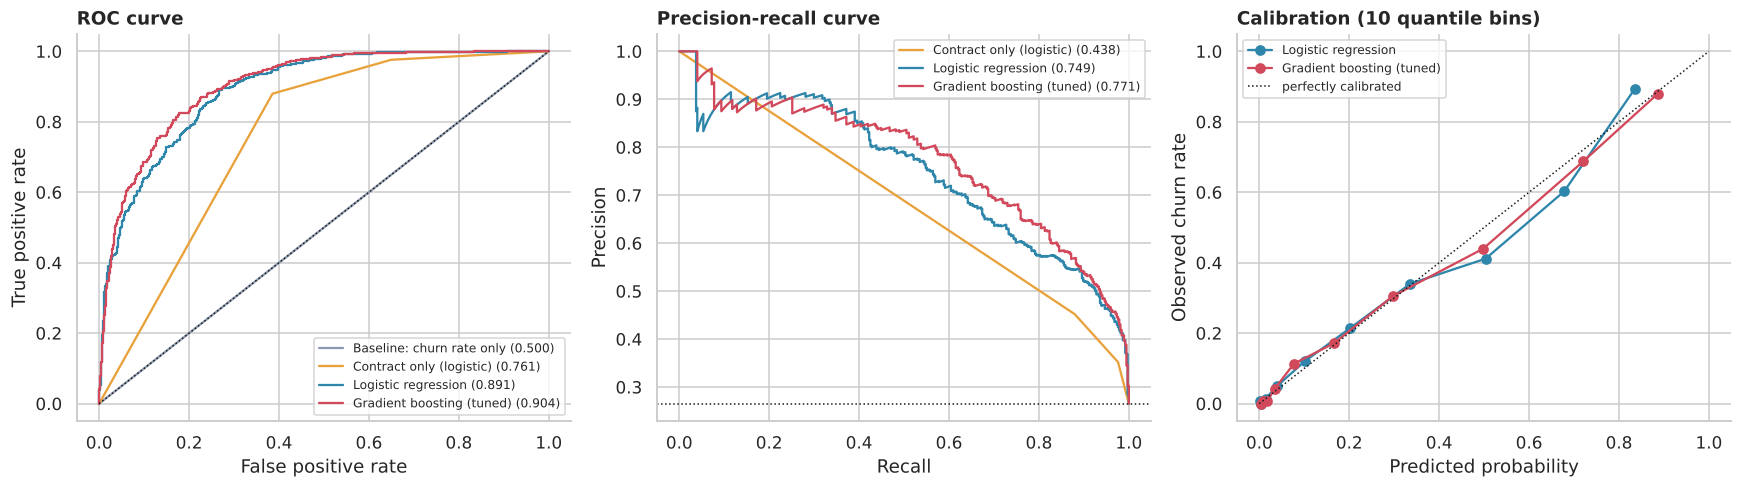

In [26]:
colors = {"Baseline: churn rate only": C_GREY, "Contract only (logistic)": "#E9A23B", "Logistic regression": C_STAY, "Gradient boosting (tuned)": C_CHURN}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for name, p in preds.items():
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    if name.startswith("Baseline"):
        continue                                   # a constant score has no meaningful PR curve; its level is the dotted line
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, color=colors[name], label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve")
for a in axes[:2]: a.legend(fontsize=8, loc="lower right" if a is axes[0] else "upper right")

for name in ["Logistic regression", "Gradient boosting (tuned)"]:
    frac_pos, mean_pred = calibration_curve(y_test, preds[name], n_bins=10, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, "o-", color=colors[name], label=name)
axes[2].plot([0, 1], [0, 1], "k:", lw=1, label="perfectly calibrated")
axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed churn rate"); axes[2].set_title("Calibration (10 quantile bins)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.4 Is the difference real? Bootstrap confidence intervals

A test set is a sample, so every metric has uncertainty. A **paired bootstrap** resamples the test set many times and answers "is gradient boosting *really* better than logistic regression, or is that noise?"

In [27]:
def paired_bootstrap(metric, y_true, a, b, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, a, b = np.asarray(y_true), np.asarray(a), np.asarray(b)
    sa, sb, d = [], [], []
    for _ in range(n):
        s = rng.integers(0, len(y_true), len(y_true))
        if y_true[s].min() == y_true[s].max():
            continue
        va, vb = metric(y_true[s], a[s]), metric(y_true[s], b[s])
        sa.append(va); sb.append(vb); d.append(va - vb)
    q = lambda v: np.percentile(v, [2.5, 97.5])
    return q(sa), q(sb), q(d)

p_hgb, p_lr = preds["Gradient boosting (tuned)"], preds["Logistic regression"]
for label, metric in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score)]:
    ci_h, ci_l, ci_d = paired_bootstrap(metric, y_test, p_hgb, p_lr)
    verdict = "difference is distinguishable from zero" if (ci_d[0] > 0 or ci_d[1] < 0) else "difference is within noise"
    print(f"{label}:  GBM [{ci_h[0]:.3f}, {ci_h[1]:.3f}]   LR [{ci_l[0]:.3f}, {ci_l[1]:.3f}]   GBM - LR: [{ci_d[0]:+.3f}, {ci_d[1]:+.3f}]  -> {verdict}")

ROC-AUC:  GBM [0.887, 0.920]   LR [0.873, 0.909]   GBM - LR: [+0.005, +0.022]  -> difference is distinguishable from zero


PR-AUC:  GBM [0.723, 0.812]   LR [0.700, 0.794]   GBM - LR: [-0.006, +0.049]  -> difference is within noise


### 7.5 From scores to a ranked list: gains and lift by decile

Business teams do not think in AUC; they think "if I call the top 10% of the list, how many leavers do I reach?"

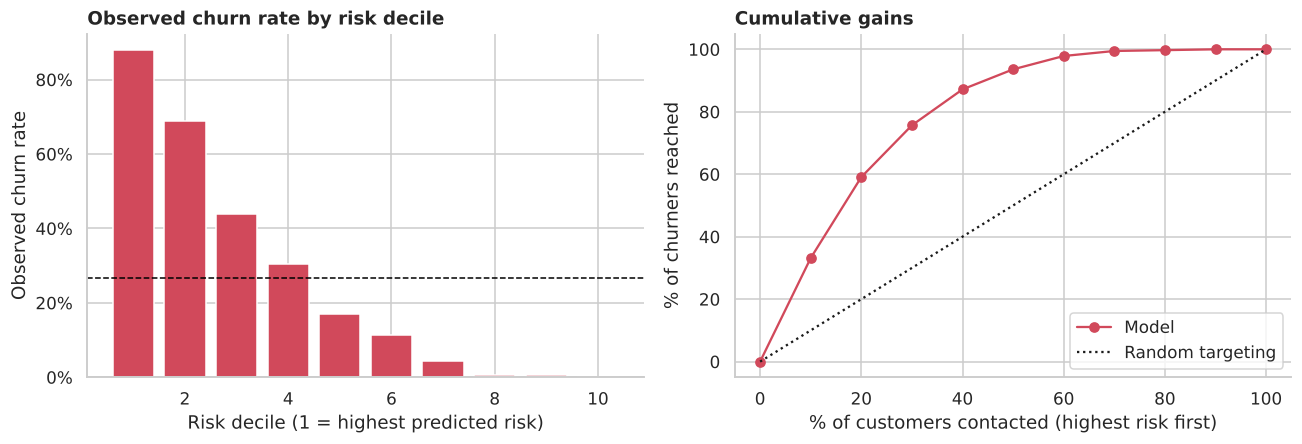

Contacting only the **top 10%** of customers reaches **33% of churners** (lift 3.3x); the **top 30%** reaches **76%**.

,customers,churners,avg_score,churn_rate,lift,cum_capture
decile,,,,,,
1,141,124,0.886,0.879,3.313,0.332
2,141,97,0.721,0.688,2.592,0.591
3,141,62,0.498,0.440,1.657,0.757
4,141,43,0.297,0.305,1.149,0.872
5,141,24,0.166,0.170,0.641,0.936
6,140,16,0.077,0.114,0.431,0.979
7,141,6,0.034,0.043,0.160,0.995
8,141,1,0.018,0.007,0.027,0.997
9,141,1,0.008,0.007,0.027,1.000


In [28]:
def gain_table(y_true, score, bins=10):
    t = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(score)}).sort_values("p", ascending=False).reset_index(drop=True)
    t["decile"] = pd.qcut(np.arange(len(t)), bins, labels=range(1, bins + 1))
    g = t.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"), avg_score=("p", "mean"))
    g["churn_rate"] = g.churners / g.customers
    g["lift"] = g.churn_rate / t.y.mean()
    g["cum_capture"] = g.churners.cumsum() / g.churners.sum()
    return g

gains = gain_table(y_test, p_hgb)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(gains.index.astype(int), gains.churn_rate, color=C_CHURN)
axes[0].axhline(y_test.mean(), color="black", ls="--", lw=1); axes[0].set_xlabel("Risk decile (1 = highest predicted risk)"); axes[0].set_ylabel("Observed churn rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[0].set_title("Observed churn rate by risk decile")
axes[1].plot(np.r_[0, np.arange(1, 11) * 10], np.r_[0, gains.cum_capture * 100], "o-", color=C_CHURN, label="Model")
axes[1].plot([0, 100], [0, 100], "k:", label="Random targeting"); axes[1].set_xlabel("% of customers contacted (highest risk first)")
axes[1].set_ylabel("% of churners reached"); axes[1].set_title("Cumulative gains"); axes[1].legend()
plt.tight_layout(); plt.show()

d1, d2 = gains.iloc[0], gains.iloc[:2]
display(Markdown(f"Contacting only the **top 10%** of customers reaches **{gains.cum_capture.iloc[0]:.0%} of churners** (lift {d1.lift:.1f}x); "
                 f"the **top 30%** reaches **{gains.cum_capture.iloc[2]:.0%}**."))
gains.round(3)

### 7.6 Choosing a classification threshold *without touching the test set*

A threshold turns probabilities into yes/no decisions. We pick it on **out-of-fold predictions from the training set**, then apply it once to the test set. (Section 10 chooses the *business-optimal* threshold from costs instead; this one maximises F1 and is shown to illustrate the mechanics.)

In [29]:
final_model = fitted["Gradient boosting (tuned)"][0]
oof = cross_val_predict(clone(final_model), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
threshold_f1 = float(thr[np.argmax(f1s)])

pred_class = (p_hgb >= threshold_f1).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, pred_class), index=["Actual: stayed", "Actual: churned"], columns=["Predicted: stay", "Predicted: churn"])
display(cm)
print(f"Threshold {threshold_f1:.2f} (chosen on training OOF)  ->  precision {precision_score(y_test, pred_class):.2f} | "
      f"recall {recall_score(y_test, pred_class):.2f} | F1 {f1_score(y_test, pred_class):.2f}")

,Predicted: stay,Predicted: churn
Actual: stayed,902,133
Actual: churned,92,282


Threshold 0.40 (chosen on training OOF)  ->  precision 0.68 | recall 0.75 | F1 0.71


### 7.7 Robustness: feature-set ablation

"Does the result survive removing suspicious features?" A short ablation answers the leakage questions raised in Sections 3 and 4 with evidence instead of opinion.

In [30]:
no_tenure = [c for c in FEATURES if c != "tenure_in_months"]
sets = {"A  Production + cumulative totals": FEATURES + CUMULATIVE,
        "B  Production feature set": FEATURES,
        "C  B without tenure": no_tenure,
        "D  B without age": [c for c in FEATURES if c != "age"]}
rows = []
for label, cols in sets.items():
    train_part = cust.loc[X_train.index, cols]
    lr_m = make_model("lr", cols).set_params(model__C=lr_search.best_params_["model__C"])
    gb_m = make_model("hgb", cols).set_params(**hgb_search.best_params_)
    rows.append({"feature set": label, "n_features": len(cols),
                 "CV ROC-AUC logistic": cross_val_score(lr_m, train_part, y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean(),
                 "CV ROC-AUC boosting": cross_val_score(gb_m, train_part, y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean()})
ablation = pd.DataFrame(rows).set_index("feature set")
display(ablation)
display(Markdown(f"* Adding the cumulative totals changes ROC-AUC by **{ablation.iloc[0,1]-ablation.iloc[1,1]:+.3f}** (logistic) / **{ablation.iloc[0,2]-ablation.iloc[1,2]:+.3f}** (boosting): they add nothing, so dropping them is free.\n"
                 f"* Removing tenure costs **{ablation.iloc[2,2]-ablation.iloc[1,2]:+.3f}**: tenure helps, but the model is **not dependent on it**; contract, services and referrals carry most of the signal.\n"
                 f"* Removing age changes boosting AUC by **{ablation.iloc[3,2]-ablation.iloc[1,2]:+.3f}**: if policy requires, age can be dropped at little cost."))

,n_features,CV ROC-AUC logistic,CV ROC-AUC boosting
feature set,,,
A Production + cumulative totals,31,0.899,0.910
B Production feature set,26,0.898,0.910
C B without tenure,25,0.894,0.905
D B without age,25,0.896,0.904


* Adding the cumulative totals changes ROC-AUC by **+0.001** (logistic) / **+0.000** (boosting): they add nothing, so dropping them is free.
* Removing tenure costs **-0.005**: tenure helps, but the model is **not dependent on it**; contract, services and referrals carry most of the signal.
* Removing age changes boosting AUC by **-0.006**: if policy requires, age can be dropped at little cost.

## 8. Interpreting the model and checking it is fair

> **Skill:** explain a model at three levels, **global** (what matters overall), **shape** (how a feature changes risk) and **local** (why this customer), then check performance across groups.
> **Daily-work use:** every model has to be defended to a manager, a regulator or a sceptical colleague.
> **Pitfall:** reading feature importance as causation, trusting impurity-based importances, or only looking at overall accuracy and missing a group where the model is badly wrong.

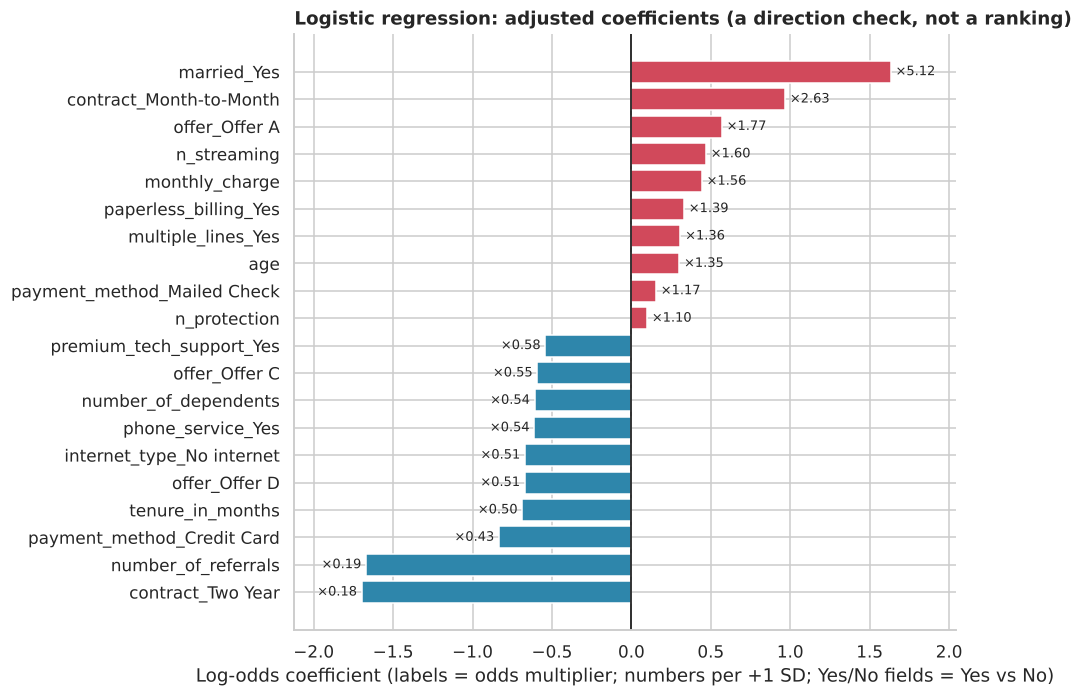

In [31]:
# (1) Global, transparent: logistic regression coefficients -> odds ratios
lr_pipe = fitted["Logistic regression"][0]
names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=names).sort_values()
extremes = pd.concat([coefs.head(10), coefs.tail(10)])

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(extremes.index, extremes.values, color=[C_STAY if v < 0 else C_CHURN for v in extremes.values])
for i, v in enumerate(extremes.values):
    ax.text(v + (0.03 if v > 0 else -0.03), i, f"×{np.exp(v):.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8.5)
ax.axvline(0, color="black", lw=1); ax.set_xlim(extremes.min() * 1.25, extremes.max() * 1.25)
ax.set_xlabel("Log-odds coefficient (labels = odds multiplier; numbers per +1 SD; Yes/No fields = Yes vs No)")
ax.set_title("Logistic regression: adjusted coefficients (a direction check, not a ranking)")
plt.tight_layout(); plt.show()

In [32]:
# Reading coefficients responsibly: compare adjusted coefficients with raw rates
notes = []
for name, raw_level in [("offer_Offer A", ("offer", "Offer A")), ("married_Yes", ("married", "Yes"))]:
    if name in coefs.index:
        notes.append(f"* `{name}`: raw churn {r(*raw_level):.0%} (overall {base_rate:.0%}) but logistic coefficient {coefs[name]:+.2f} (odds x{np.exp(coefs[name]):.2f}).")
display(Markdown("**Raw vs adjusted: a warning label for coefficients**\n\n" + "\n".join(notes) + """

These can disagree because a coefficient answers a different question: *"what does this feature add once tenure, contract, referrals, dependents and everything else are held fixed?"* Offer A customers and married customers differ on those other factors, and correlated features share (and sometimes flip) credit. **Never tell a story from one coefficient.** Use coefficients for direction checks, and rely on permutation importance and partial dependence (next) for what actually drives the model."""))

**Raw vs adjusted: a warning label for coefficients**

* `offer_Offer A`: raw churn 7% (overall 27%) but logistic coefficient +0.57 (odds x1.77).
* `married_Yes`: raw churn 20% (overall 27%) but logistic coefficient +1.63 (odds x5.12).

These can disagree because a coefficient answers a different question: *"what does this feature add once tenure, contract, referrals, dependents and everything else are held fixed?"* Offer A customers and married customers differ on those other factors, and correlated features share (and sometimes flip) credit. **Never tell a story from one coefficient.** Use coefficients for direction checks, and rely on permutation importance and partial dependence (next) for what actually drives the model.

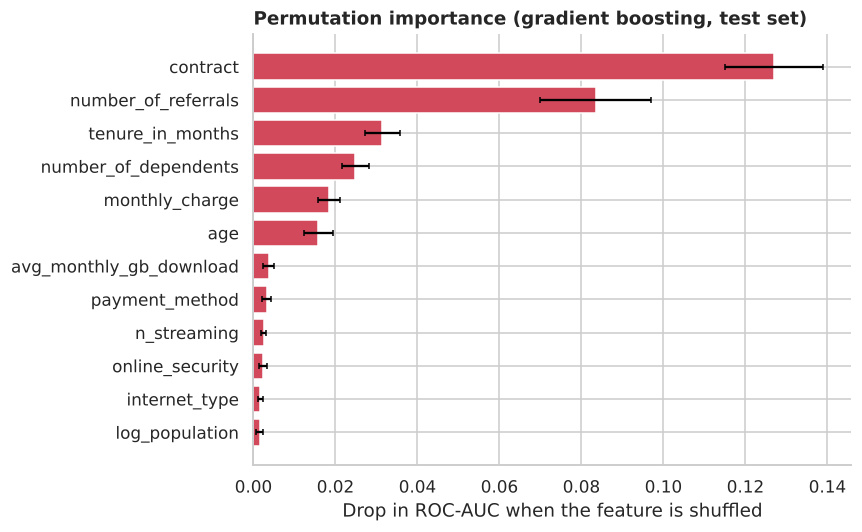

In [33]:
# (2) Global, model-agnostic: permutation importance on the TEST set (how much does AUC drop if a feature is shuffled?)
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.feature, top.importance, xerr=top["std"], color=C_CHURN, ecolor="black", capsize=2)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled"); ax.set_title("Permutation importance (gradient boosting, test set)")
plt.tight_layout(); plt.show()

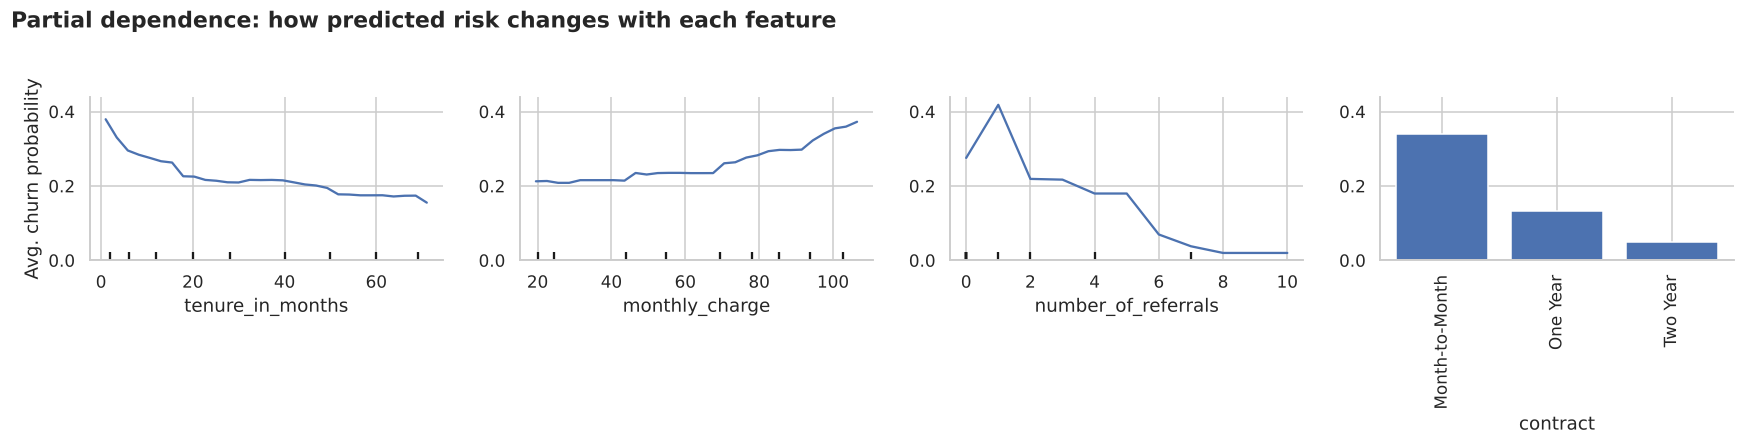

In [34]:
# (3) Shape: partial dependence = average predicted risk as one feature varies
X_pdp = X_test.astype({c: float for c in NUM_FEATURES})           # sklearn refuses integer columns in partial dependence
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
PartialDependenceDisplay.from_estimator(final_model, X_pdp, ["tenure_in_months", "monthly_charge", "number_of_referrals", "contract"],
                                        categorical_features=["contract"], kind="average", ax=axes, grid_resolution=30)
axes[0].set_ylabel("Avg. churn probability")
for a in axes[1:]:
    a.set_ylabel("")
fig.suptitle("Partial dependence: how predicted risk changes with each feature", x=0.01, ha="left", fontweight="bold", y=1.06)
plt.tight_layout(); plt.show()

**Why several views?** Logistic coefficients are *adjusted* and *linear*, and they become unstable when features are correlated, so they are a direction check rather than a ranking. Permutation importance asks the model-agnostic question "how much does accuracy suffer without this feature?", and partial dependence shows the shape. When the views agree (contract, tenure, referrals, services), the finding is robust.

**Local explanation:** for the individual customer a retention agent will actually see, the logistic model's per-feature contributions (coefficient × value) give a plain-language "why". *For tree models in production, SHAP is the standard tool; it is listed under next steps.*

In [35]:
def explain_customer(idx, top_n=5):
    """Top drivers pushing one customer's risk up or down (logistic contributions, relative to the average customer)."""
    pre, clf = lr_pipe.named_steps["prep"], lr_pipe.named_steps["model"]
    z = pre.transform(X_test.loc[[idx]])[0]
    contrib = pd.Series(z * clf.coef_[0], index=pre.get_feature_names_out())
    contrib = contrib[contrib.abs() > 1e-9].sort_values(key=abs, ascending=False).head(top_n)
    return contrib.rename("log-odds contribution").to_frame().assign(effect=lambda t: np.where(t.iloc[:, 0] > 0, "raises risk", "lowers risk"))

p_lr_series = pd.Series(p_lr, index=X_test.index)
for idx in p_lr_series.sort_values(ascending=False).index[:2]:
    row = cust.loc[idx]
    display(Markdown(f"**Customer {row.customer_id}**: logistic risk **{p_lr_series[idx]:.0%}** "
                     f"(contract {row.contract}, tenure {row.tenure_in_months} months, {row.internet_type}); actual outcome: **{row.customer_status}**"))
    display(explain_customer(idx))

**Customer 5567-WSELE**: logistic risk **96%** (contract Month-to-Month, tenure 3 months, Fiber Optic); actual outcome: **Churned**

,log-odds contribution,effect
married_Yes,1.633,raises risk
contract_Month-to-Month,0.968,raises risk
tenure_in_months,0.821,raises risk
phone_service_Yes,-0.611,lowers risk
number_of_referrals,0.529,raises risk


**Customer 1363-TXLSL**: logistic risk **96%** (contract Month-to-Month, tenure 1 months, Fiber Optic); actual outcome: **Churned**

,log-odds contribution,effect
married_Yes,1.633,raises risk
number_of_referrals,1.084,raises risk
contract_Month-to-Month,0.968,raises risk
tenure_in_months,0.877,raises risk
phone_service_Yes,-0.611,lowers risk


### 8.1 Slice evaluation: does the model work equally well for every group?

An overall AUC can hide a group where the model is poorly *calibrated* (systematically over- or under-predicting). We check slices, **including `gender` and age, which the model does not use as inputs or uses with caution**; evaluating on sensitive attributes you excluded is standard fairness practice.

In [36]:
test_frame = cust.loc[X_test.index].assign(p=p_hgb)

def slice_report(col):
    out = []
    for val, g in test_frame.groupby(col, observed=True):
        ok = g[TARGET].nunique() == 2 and len(g) >= 40
        out.append({"slice": col, "group": val, "n": len(g), "actual_churn": g[TARGET].mean(), "avg_predicted": g.p.mean(),
                    "roc_auc": roc_auc_score(g[TARGET], g.p) if ok else np.nan})
    return out

slices = pd.DataFrame(sum([slice_report(c) for c in ["gender", "age_band", "contract", "internet_type", "tenure_band"]], []))
slices["calibration_gap"] = slices.avg_predicted - slices.actual_churn
slices["flag"] = np.where(slices.calibration_gap.abs() > 0.05, "check", "")
display(slices.set_index(["slice", "group"]))
worst = slices.loc[slices.calibration_gap.abs().idxmax()]
display(Markdown(f"Largest calibration gap: **{worst.slice} = {worst.group}** ({worst.calibration_gap:+.1%}, n = {worst.n}). "
                 f"Gender AUCs are {slices.loc[slices.slice == 'gender', 'roc_auc'].round(3).tolist()}: the model ranks both groups equally well."))

n  actual_churn  avg_predicted  roc_auc  \
slice         group                                                       
gender        Female          716         0.257          0.267    0.905   
              Male            693         0.274          0.275    0.903   
age_band      19-30           313         0.214          0.226    0.895   
              31-40           263         0.266          0.254    0.907   
              41-50           243         0.226          0.228    0.894   
              51-60           258         0.236          0.237    0.871   
              61-70           198         0.354          0.387    0.923   
              71-80           134         0.381          0.381    0.926   
contract      Month-to-Month  728         0.452          0.460    0.835   
              One Year        309         0.117          0.120    0.871   
              Two Year        372         0.024          0.025    0.851   
internet_type Cable           163         0.264          0.257    0.944   
              DSL             334         0.174          0.201    0.828   
              Fiber Optic     593         0.422          0.417    0.873   
              No internet     319         0.072          0.079    0.944   
tenure_band   0-6             289         0.540          0.558    0.825   
              7-12            141         0.348          0.360    0.949   
              13-24           214         0.280          0.293    0.894   
              25-48           322         0.199          0.192    0.874   
              49-72           443         0.102          0.101    0.902   

                              calibration_gap flag  
slice         group                                 
gender        Female                    0.010       
              Male                      0.001       
age_band      19-30                     0.012       
              31-40                    -0.012       
              41-50                     0.002       
              51-60                     0.000       
              61-70                     0.033       
              71-80                     0.000       
contract      Month-to-Month            0.008       
              One Year                  0.004       
              Two Year                  0.001       
internet_type Cable                    -0.007       
              DSL                       0.028       
              Fiber Optic              -0.004       
              No internet               0.007       
tenure_band   0-6                       0.018       
              7-12                      0.013       
              13-24                     0.013       
              25-48                    -0.006       
              49-72                    -0.000

Largest calibration gap: **age_band = 61-70** (+3.3%, n = 198). Gender AUCs are [0.905, 0.903]: the model ranks both groups equally well.

## 9. Segmentation: turning a model into playbooks

> **Skill:** two complementary tools. **K-Means** finds *behavioural* segments without looking at churn (marketing personas). A **shallow decision tree** finds *risk* segments by looking at churn directly, and gives rules a non-technical team can read.
> **Daily-work use:** "give me 4-5 customer groups we can plan campaigns around" is one of the most common requests an analyst gets.
> **Pitfall:** forcing clusters that are not really there. Always check cluster quality (silhouette), stability, and whether segments differ on an *outcome that matters*.

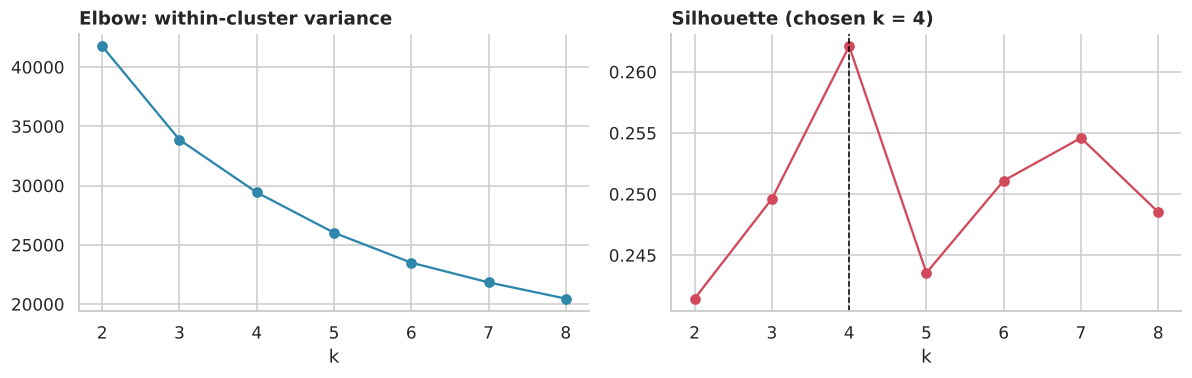

k = 4 | silhouette = 0.26 | stability across random seeds (ARI) = 1.00


In [37]:
seg = df.assign(contract_term_months=df.contract.map({"Month-to-Month": 1, "One Year": 12, "Two Year": 24}),
                has_fiber=(df.internet_type == "Fiber Optic").astype(int))
SEG_FEATURES = ["tenure_in_months", "monthly_charge", "n_protection", "n_streaming", "avg_monthly_gb_download",
                "age", "contract_term_months", "has_fiber"]
Z = StandardScaler().fit_transform(seg[SEG_FEATURES])            # K-Means is distance-based: always scale first

quality = pd.DataFrame([{"k": k, "inertia": (km := KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)).inertia_,
                         "silhouette": silhouette_score(Z, km.labels_)} for k in range(2, 9)]).set_index("k")
K = int(quality.loc[3:6, "silhouette"].idxmax())                  # best silhouette among actionable sizes (3-6)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(quality.index, quality.inertia, "o-", color=C_STAY); axes[0].set_title("Elbow: within-cluster variance"); axes[0].set_xlabel("k")
axes[1].plot(quality.index, quality.silhouette, "o-", color=C_CHURN); axes[1].axvline(K, ls="--", color="black", lw=1)
axes[1].set_title(f"Silhouette (chosen k = {K})"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
ari = adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=20, random_state=7).fit(Z).labels_)
print(f"k = {K} | silhouette = {silhouette_score(Z, km.labels_):.2f} | stability across random seeds (ARI) = {ari:.2f}")

,customers,churn_rate,avg_monthly_charge,share_of_customers,share_of_revenue,what defines it
segment,,,,,,
S1,1844,0.543,84.689,0.262,0.349,"high fiber share, high monthly charge, low contract length"
S2,1015,0.297,70.928,0.144,0.161,"high GB downloaded, low age, low contract length"
S3,2515,0.165,29.820,0.357,0.167,"low monthly charge, low fiber share, low streaming services"
S4,1669,0.092,86.729,0.237,0.323,"high protection add-ons, high tenure, high contract length"


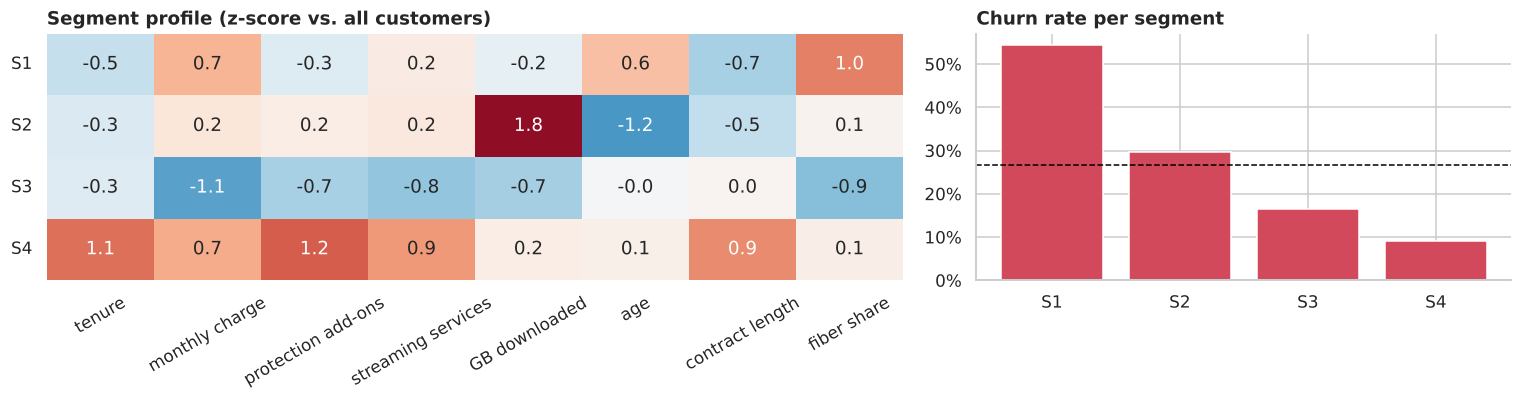

In [38]:
seg["cluster"] = km.labels_
risk_order = seg.groupby("cluster")[TARGET].mean().sort_values(ascending=False).index          # S1 = highest churn
seg["segment"] = seg.cluster.map({c: f"S{i + 1}" for i, c in enumerate(risk_order)})

prof = seg.groupby("segment").agg(customers=("customer_id", "size"), churn_rate=(TARGET, "mean"),
                                  avg_monthly_charge=("monthly_charge", "mean"), monthly_revenue=("monthly_charge", "sum"))
prof["share_of_customers"] = prof.customers / prof.customers.sum()
prof["share_of_revenue"] = prof.monthly_revenue / prof.monthly_revenue.sum()

means = seg.groupby("segment")[SEG_FEATURES].mean()
zprof = (means - seg[SEG_FEATURES].mean()) / seg[SEG_FEATURES].std()
LABELS = {"tenure_in_months": "tenure", "monthly_charge": "monthly charge", "n_protection": "protection add-ons", "n_streaming": "streaming services",
          "avg_monthly_gb_download": "GB downloaded", "age": "age", "contract_term_months": "contract length", "has_fiber": "fiber share"}
describe = lambda row: ", ".join(f"{'high' if v > 0 else 'low'} {LABELS[c]}" for c, v in row.reindex(row.abs().sort_values(ascending=False).index)[:3].items())
prof["what defines it"] = zprof.apply(describe, axis=1)
display(prof.drop(columns="monthly_revenue"))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(zprof.rename(columns=LABELS), annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, cbar=False, ax=axes[0])
axes[0].set_title("Segment profile (z-score vs. all customers)"); axes[0].set_ylabel("")
axes[0].tick_params(axis="y", rotation=0); axes[0].tick_params(axis="x", rotation=30)
axes[1].bar(prof.index, prof.churn_rate, color=C_CHURN); axes[1].axhline(base_rate, color="black", ls="--", lw=1)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[1].set_title("Churn rate per segment")
plt.tight_layout(); plt.show()

**How to read this honestly:** a silhouette around 0.2-0.3 means the segments are *useful summaries on a continuum*, not sharply separated groups. They are valuable here because they **differ strongly on churn and revenue**, which is the test that matters. Label them with business names (e.g. "new fiber month-to-monthers") when presenting.

### 9.1 Supervised risk segments: a shallow decision tree as a rulebook

A depth-4 tree with at least 100 customers per leaf produces a short list of **IF-THEN rules**. We evaluate each rule on the **test set**: rules that only look good on training data are discarded.

In [39]:
tree_pre = make_preprocessor(NUM_FEATURES, CAT_FEATURES, scale=False)
Xt_train, Xt_test = tree_pre.fit_transform(X_train), tree_pre.transform(X_test)
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, random_state=SEED).fit(Xt_train, y_train)
feat_names = tree_pre.get_feature_names_out()

def format_rule(path):
    """Merge repeated bounds on the same feature so rules read like 'tenure_in_months <= 16.5'."""
    lo, hi, cats = {}, {}, []
    for f, op, v in path:
        if op == "<=":
            hi[f] = min(hi.get(f, np.inf), v)
        elif op == ">":
            lo[f] = max(lo.get(f, -np.inf), v)
        elif (f, op, v) not in cats:
            cats.append((f, op, v))
    parts = [f"{f} {op} {v}" for f, op, v in cats]
    for f in dict.fromkeys(p[0] for p in path if p[1] in ("<=", ">")):
        if f in lo and f in hi:
            parts.append(f"{lo[f]:.1f} < {f} <= {hi[f]:.1f}")
        elif f in hi:
            parts.append(f"{f} <= {hi[f]:.1f}")
        else:
            parts.append(f"{f} > {lo[f]:.1f}")
    return " AND ".join(parts) or "all customers"

def leaf_rules(tree, names, cat_cols):
    """Walk the fitted tree and return {leaf_id: plain-language rule}."""
    t, rules = tree.tree_, {}
    def walk(node, path):
        if t.children_left[node] == -1:
            rules[node] = format_rule(path)
            return
        f = names[t.feature[node]]
        col = max((c for c in cat_cols if f.startswith(c + "_")), key=len, default=None)
        if col:                                   # one-hot dummy: split is "has this category" vs "does not"
            left, right = (col, "!=", f[len(col) + 1:]), (col, "=", f[len(col) + 1:])
        else:
            left, right = (f, "<=", float(t.threshold[node])), (f, ">", float(t.threshold[node]))
        walk(t.children_left[node], path + [left]); walk(t.children_right[node], path + [right])
    walk(0, [])
    return rules

rules = leaf_rules(tree, feat_names, CAT_FEATURES)
leaf = pd.DataFrame({"leaf": np.r_[tree.apply(Xt_train), tree.apply(Xt_test)], "churn": np.r_[y_train, y_test],
                     "set": ["train"] * len(y_train) + ["test"] * len(y_test)})
tbl = leaf.pivot_table(index="leaf", columns="set", values="churn", aggfunc=["size", "mean"])
tbl.columns = [f"{a}_{b}" for a, b in tbl.columns]
tbl = tbl.rename(columns={"size_train": "n_train", "size_test": "n_test", "mean_train": "churn_train", "mean_test": "churn_test"})
tbl.insert(0, "rule", tbl.index.map(rules))
tbl = tbl.sort_values("churn_train", ascending=False)[["rule", "n_train", "churn_train", "n_test", "churn_test"]]

pd.set_option("display.max_colwidth", 150)
display(Markdown(f"**Highest-risk rules** (tree test ROC-AUC = {roc_auc_score(y_test, tree.predict_proba(Xt_test)[:, 1]):.3f} versus {roc_auc_score(y_test, p_hgb):.3f} for boosting: "
                 "the price of a fully readable model)"))
display(tbl.head(4).reset_index(drop=True))
display(Markdown("**Lowest-risk rules**"))
display(tbl.tail(3).reset_index(drop=True))

**Highest-risk rules** (tree test ROC-AUC = 0.863 versus 0.904 for boosting: the price of a fully readable model)

,rule,n_train,churn_train,n_test,churn_test
0,contract = Month-to-Month AND age > 64.5 AND tenure_in_months <= 3.5,108,0.963,24,0.833
1,contract = Month-to-Month AND age > 64.5 AND 3.5 < tenure_in_months <= 16.5,114,0.860,38,0.895
2,contract = Month-to-Month AND age > 64.5 AND 16.5 < tenure_in_months <= 33.5,100,0.780,21,0.905
3,contract = Month-to-Month AND age > 64.5 AND tenure_in_months > 33.5,111,0.667,26,0.538


**Lowest-risk rules**

,rule,n_train,churn_train,n_test,churn_test
0,contract != Month-to-Month AND number_of_referrals > 5.5 AND avg_monthly_long_distance_charges > 41.3,100,0.010,28,0.000
1,contract != Month-to-Month AND number_of_referrals > 5.5 AND avg_monthly_long_distance_charges <= 41.3,574,0.000,131,0.015
2,contract != Month-to-Month AND 1.5 < number_of_referrals <= 5.5 AND number_of_dependents > 0.5,230,0.000,64,0.000


## 10. From model to decision: the economics of a retention campaign

> **Skill:** convert a probability into **expected money**, choose *who* to contact by expected value (not by an arbitrary "top 20%"), and test how sensitive the answer is to your assumptions.
> **Daily-work use:** the step that separates a data scientist whose model sits in a notebook from one whose model changes a decision.
> **Pitfall:** presenting AUC to a business audience, hiding assumptions, or giving a single number without showing what would change it.

**Logic.** Contacting customer *i* costs `COST`. If *i* would have left (probability `p`), the offer saves them with probability `SAVE_RATE`, preserving margin on `HORIZON` months of revenue:

> **expected net value of contacting i = p × SAVE_RATE × value − COST**, where **value = max(monthly charge, 0) × HORIZON × MARGIN**

Contact exactly the customers whose expected net value is positive. **These four numbers are assumptions**, not facts from the data. Replace them with finance's figures and check the sensitivity analysis below.

In [40]:
# ── Business assumptions (edit these) ─────────────────────────────────────────
COST = 15.0        # $ per retention contact (agent time + incentive)
SAVE_RATE = 0.30   # share of would-be churners who stay after being contacted
MARGIN = 0.50      # gross margin on recurring revenue
HORIZON = 12       # months of revenue preserved when a customer is saved

value = cust.loc[X_test.index, "monthly_charge"].clip(lower=0).to_numpy() * HORIZON * MARGIN
churn_t = y_test.to_numpy()
p = p_hgb
ev = p * SAVE_RATE * value - COST                                   # expected net value of contacting each customer
realized = churn_t * SAVE_RATE * value - COST                       # what contacting each customer *actually* would have yielded (expected over save lottery)

def policy(name, mask):
    mask = np.asarray(mask, bool)
    gross = (churn_t * SAVE_RATE * value)[mask].sum(); spend = COST * mask.sum()
    return {"policy": name, "customers contacted": int(mask.sum()), "campaign cost": spend, "retained margin": gross,
            "net profit": gross - spend, "ROI": (gross - spend) / spend if spend else np.nan}

m2m = (cust.loc[X_test.index, "contract"] == "Month-to-Month").to_numpy()
top20 = np.argsort(-p).argsort() < int(0.2 * len(p))
policies = pd.DataFrame([policy("Contact nobody", np.zeros(len(p), bool)), policy("Contact everyone", np.ones(len(p), bool)),
                         policy("Rule: all month-to-month customers", m2m), policy("Model: top 20% by probability", top20),
                         policy("Model: expected value > 0", ev > 0), policy("Oracle (only true churners; unattainable bound)", churn_t == 1)]).set_index("policy")
display(policies.style.format({"campaign cost": "${:,.0f}", "retained margin": "${:,.0f}", "net profit": "${:,.0f}", "ROI": "{:.1f}x"}))

,customers contacted,campaign cost,retained margin,net profit,ROI
policy,,,,,
Contact nobody,0,$0,$0,$0,nanx
Contact everyone,1409,"$21,135","$49,125","$27,990",1.3x
Rule: all month-to-month customers,728,"$10,920","$41,789","$30,869",2.8x
Model: top 20% by probability,281,"$4,215","$30,656","$26,441",6.3x
Model: expected value > 0,619,"$9,285","$45,564","$36,279",3.9x
Oracle (only true churners; unattainable bound),374,"$5,610","$49,125","$43,515",7.8x


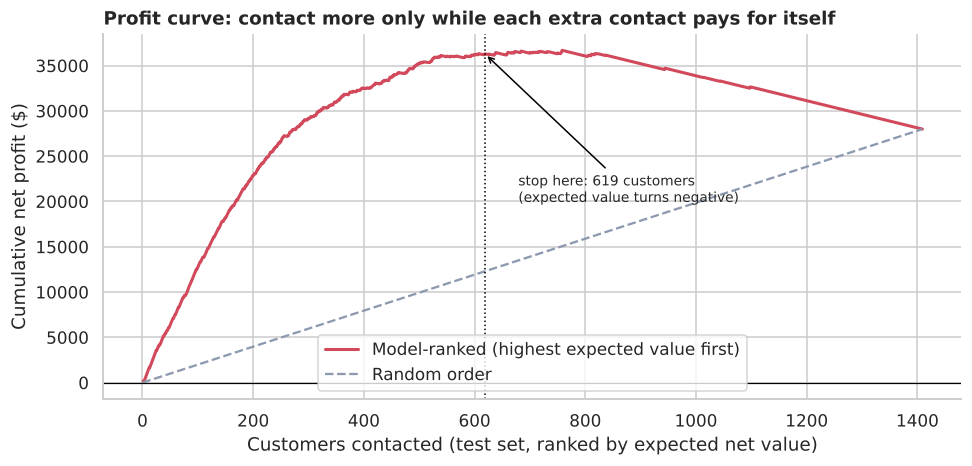

On the test set the **expected-value policy nets $36,279** by contacting 619 of 1,409 customers (vs $27,990 if we contact everyone and $30,869 for the simple month-to-month rule). It captures **83% of the theoretical maximum**.

In [41]:
order = np.argsort(-ev)
cum_net = np.cumsum(realized[order])
k_star = int((ev > 0).sum())

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(np.arange(1, len(p) + 1), cum_net, color=C_CHURN, lw=2, label="Model-ranked (highest expected value first)")
ax.plot([0, len(p)], [0, realized.mean() * len(p)], color=C_GREY, ls="--", label="Random order")
ax.axvline(k_star, color="black", ls=":", lw=1); ax.axhline(0, color="black", lw=0.8)
ax.annotate(f"stop here: {k_star} customers\n(expected value turns negative)", (k_star, cum_net[k_star - 1]), xytext=(k_star + 60, cum_net[k_star - 1] * 0.55),
            arrowprops={"arrowstyle": "->", "color": "black"}, fontsize=9)
ax.set_xlabel("Customers contacted (test set, ranked by expected net value)"); ax.set_ylabel("Cumulative net profit ($)")
ax.set_title("Profit curve: contact more only while each extra contact pays for itself"); ax.legend(loc="lower center")
plt.tight_layout(); plt.show()

best, everyone = policies.loc["Model: expected value > 0", "net profit"], policies.loc["Contact everyone", "net profit"]
rule = policies.loc["Rule: all month-to-month customers", "net profit"]
display(Markdown(f"On the test set the **expected-value policy nets ${best:,.0f}** by contacting {k_star} of {len(p):,} customers "
                 f"(vs ${everyone:,.0f} if we contact everyone and ${rule:,.0f} for the simple month-to-month rule). "
                 f"It captures **{best / policies.loc['Oracle (only true churners; unattainable bound)', 'net profit']:.0%} of the theoretical maximum**."))

### 10.1 Sensitivity: how fragile is the answer?

The save rate and contact cost are the least certain inputs. Re-deriving the *optimal* policy for each combination shows whether the campaign is worth running under pessimistic assumptions, and what a pilot (A/B test) needs to measure.

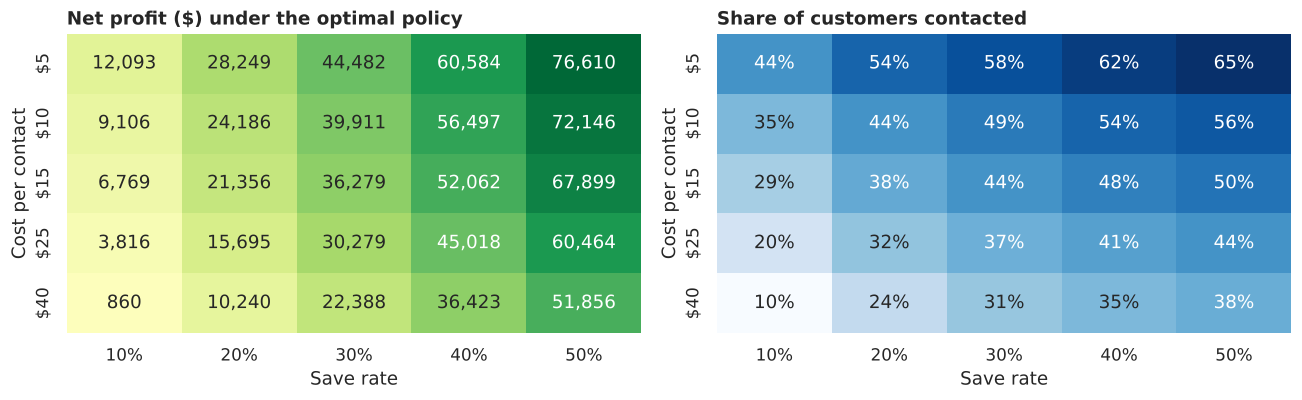

Even in the most pessimistic corner (10% save rate, $40 per contact) the optimal policy yields **$860**: the policy automatically contacts fewer people as the economics get worse, so it degrades gracefully rather than losing money.

In [42]:
save_grid, cost_grid = [0.10, 0.20, 0.30, 0.40, 0.50], [5, 10, 15, 25, 40]
profit_grid = pd.DataFrame(index=[f"${c}" for c in cost_grid], columns=[f"{s:.0%}" for s in save_grid], dtype=float)
share_grid = profit_grid.copy()
for c in cost_grid:
    for s in save_grid:
        contact = p * s * value - c > 0
        profit_grid.loc[f"${c}", f"{s:.0%}"] = (churn_t * s * value - c)[contact].sum()
        share_grid.loc[f"${c}", f"{s:.0%}"] = contact.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(profit_grid, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, cbar=False, ax=axes[0])
axes[0].set_title("Net profit ($) under the optimal policy"); axes[0].set_xlabel("Save rate"); axes[0].set_ylabel("Cost per contact")
sns.heatmap(share_grid, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Share of customers contacted"); axes[1].set_xlabel("Save rate"); axes[1].set_ylabel("Cost per contact")
plt.tight_layout(); plt.show()
worst_case = profit_grid.iloc[-1, 0]
display(Markdown(f"Even in the most pessimistic corner (10% save rate, $40 per contact) the optimal policy yields **${worst_case:,.0f}**: "
                 "the policy automatically contacts fewer people as the economics get worse, so it degrades gracefully rather than losing money."))

### 10.2 A BI-ready scoring table

The last mile is a table other tools can read. **Honest scoring rule:** every customer gets an *out-of-fold* probability, i.e. it comes from a model that never saw that customer. Scoring customers with a model trained on them would overstate accuracy and distort the contact list.

In [43]:
oof_all = cross_val_predict(clone(final_model), X, y, cv=cv, method="predict_proba")[:, 1]

cols_out = ["customer_id", "customer_status", "contract", "internet_type", "tenure_in_months", "monthly_charge"]
scored = cust[cols_out].assign(churn_probability=oof_all)
scored["value_at_stake"] = scored.monthly_charge.clip(lower=0) * HORIZON * MARGIN
scored["expected_net_value_of_contact"] = scored.churn_probability * SAVE_RATE * scored.value_at_stake - COST
scored["risk_tier"] = pd.cut(scored.churn_probability, [-0.01, 0.2, 0.5, 1.0], labels=["Low", "Medium", "High"])
scored["recommended_action"] = np.where((scored.customer_status != "Churned") & (scored.expected_net_value_of_contact > 0), "Contact", "No action")

Path("outputs").mkdir(exist_ok=True)
scored.to_csv("outputs/scored_customers.csv", index=False)

active = scored[scored.customer_status != "Churned"]
n_contact = int((active.recommended_action == "Contact").sum())
exp_profit = active.loc[active.recommended_action == "Contact", "expected_net_value_of_contact"].sum()
display(Markdown(f"**{len(active):,} active customers** (Stayed + Joined) scored; **{n_contact:,} recommended for contact**, expected net value ≈ **${exp_profit:,.0f}** under the assumptions above. "
                 "Saved to `outputs/scored_customers.csv` for Power BI / Tableau / Excel."))
active.sort_values("expected_net_value_of_contact", ascending=False).head(8).round(3)

**5,174 active customers** (Stayed + Joined) scored; **1,495 recommended for contact**, expected net value ≈ **$55,266** under the assumptions above. Saved to `outputs/scored_customers.csv` for Power BI / Tableau / Excel.

,customer_id,customer_status,contract,internet_type,tenure_in_months,monthly_charge,churn_probability,value_at_stake,expected_net_value_of_contact,risk_tier,recommended_action
4254,5995-SNNEW,Stayed,Month-to-Month,Fiber Optic,23,104.450,0.938,626.700,161.413,High,Contact
1413,2081-VEYEH,Joined,Month-to-Month,Fiber Optic,3,107.950,0.893,647.700,158.615,High,Contact
4079,5760-IFJOZ,Joined,Month-to-Month,Fiber Optic,3,107.950,0.866,647.700,153.177,High,Contact
3002,4298-OYIFC,Stayed,Month-to-Month,Fiber Optic,15,103.450,0.886,620.700,150.008,High,Contact
1452,2144-BFDSO,Stayed,Month-to-Month,Fiber Optic,50,108.750,0.841,652.500,149.573,High,Contact
6448,9129-UXERG,Stayed,Month-to-Month,Fiber Optic,18,103.600,0.859,621.600,145.257,High,Contact
697,1028-FFNJK,Stayed,Month-to-Month,Fiber Optic,30,101.500,0.873,609.000,144.497,High,Contact
4513,6362-QHAFM,Stayed,One Year,Fiber Optic,42,108.300,0.809,649.800,142.636,High,Contact


## 11. Executive summary and limitations

> **Skill:** lead with the answer, quantify it, state what you are unsure of, and say what you would do next. Numbers below are computed from the notebook, so they cannot go stale.

In [44]:
auc, pr, lift = test_table.loc["Gradient boosting (tuned)", ["ROC-AUC", "PR-AUC", "lift@20%"]]
cap20 = test_table.loc["Gradient boosting (tuned)", "churners captured@20%"]
display(Markdown(f"""
### Findings

1. **{base_rate:.0%} of customers churned during the quarter**, taking **${lost_mrr:,.0f} of monthly recurring revenue** with them.
2. **Contract type is the strongest lever.** Month-to-month customers churn at {r('contract','Month-to-Month'):.0%} versus {r('contract','Two Year'):.0%} on two-year contracts. The month-to-month **Fiber** segment alone is {n_hot / len(cust):.0%} of customers but **{churners_hot / cust[TARGET].sum():.0%} of churners**.
3. **Risk is front-loaded.** Only {ret_contract.loc['Month-to-Month','retained_12m']:.0%} of month-to-month customers survive 12 months (vs {ret_contract.loc['Two Year','retained_12m']:.0%} on two-year plans). The first six months are the retention window.
4. **Reasons are actionable.** Competitors drive {comp:.0%} of departures (devices, offers, speed, data). Support and service attitude is a further, fully controllable share.
5. **The model ranks well and is robust.** On held-out data: ROC-AUC **{auc:.3f}**, PR-AUC **{pr:.3f}**, and the top 20% of customers by risk contain **{cap20:.0%} of churners** (lift {lift:.1f}x). Removing tenure or the cumulative totals barely changes this.
6. **A score becomes money when paired with economics.** Contacting customers whose expected value is positive nets **${best:,.0f}** on the test set, {best / max(rule, 1):.1f}x the simple month-to-month rule; **{n_contact:,} active customers** are currently recommended for contact.

### Recommendations
* **Convert month-to-month customers to 1-2 year contracts during months 1-6** (the highest-leverage structural fix).
* **Review the Fiber product and Offer E.** Both are over-represented among churners; investigate price/performance versus competitors.
* **Fix the support experience.** Coach on 'attitude' issues and test bundling Premium Tech Support for new internet customers.
* **Run the retention campaign on the model's contact list, as an A/B test.** A holdout group measures the *true* save rate, replacing the 30% assumption with evidence.
"""))


### Findings

1. **27% of customers churned during the quarter**, taking **$137,087 of monthly recurring revenue** with them.
2. **Contract type is the strongest lever.** Month-to-month customers churn at 46% versus 3% on two-year contracts. The month-to-month **Fiber** segment alone is 27% of customers but **59% of churners**.
3. **Risk is front-loaded.** Only 68% of month-to-month customers survive 12 months (vs 100% on two-year plans). The first six months are the retention window.
4. **Reasons are actionable.** Competitors drive 45% of departures (devices, offers, speed, data). Support and service attitude is a further, fully controllable share.
5. **The model ranks well and is robust.** On held-out data: ROC-AUC **0.904**, PR-AUC **0.771**, and the top 20% of customers by risk contain **59% of churners** (lift 2.9x). Removing tenure or the cumulative totals barely changes this.
6. **A score becomes money when paired with economics.** Contacting customers whose expected value is positive nets **$36,279** on the test set, 1.2x the simple month-to-month rule; **1,495 active customers** are currently recommended for contact.

### Recommendations
* **Convert month-to-month customers to 1-2 year contracts during months 1-6** (the highest-leverage structural fix).
* **Review the Fiber product and Offer E.** Both are over-represented among churners; investigate price/performance versus competitors.
* **Fix the support experience.** Coach on 'attitude' issues and test bundling Premium Tech Support for new internet customers.
* **Run the retention campaign on the model's contact list, as an A/B test.** A holdout group measures the *true* save rate, replacing the 30% assumption with evidence.


### Limitations (what I would tell a stakeholder honestly)

* **Snapshot, not history.** We see one end-of-quarter status. Features such as add-on services may have been recorded at or after the moment of churn, so the model describes *who looks like a churner*; a production system should be trained on features as of a date **before** the outcome window.
* **Correlation, not causation.** Offers, tech support and contract type are chosen by customers (or sold to specific customers). Only a randomised experiment can say what a retention offer *causes*.
* **Assumption-driven economics.** `COST`, `SAVE_RATE`, `MARGIN` and `HORIZON` are illustrative. The sensitivity analysis shows the decision logic, not the real profit.
* **Probabilities depend on prevalence.** They are calibrated to this dataset's churn rate; if the real quarterly rate differs, recalibrate before using the profit calculation.
* **Partial exposure.** `Joined` customers were active for only part of the quarter, so their observed churn understates a full quarter of risk.
* **Sensitive attribute.** `age` is predictive but sensitive; confirm that policy and law allow it to influence customer treatment (an ablation shows the cost of removing it is small).
* **One market, one quarter.** Everything is California, Q2 2022; check for drift before reusing on another period or region.

### Next steps beyond this notebook
1. **SHAP values** for per-customer explanations from the boosting model (`pip install shap`).
2. **Monitoring**: track score distribution, calibration and churn rate monthly; retrain when they drift.
3. **Uplift modelling** after the A/B test: target customers who are *persuadable*, not merely likely to leave.
4. **Productionise**: move `build_features` and the pipeline into a `.py` module with tests, schedule scoring, and push `scored_customers.csv` to the BI layer.
5. **Time-aware validation** once dated snapshots are available (train on the past, validate on the future).

---
*Tip for showcasing: keep this notebook as the "long form", then write a one-page README with the executive summary above, the profit-curve chart and the segment heatmap, and link to it from your portfolio.*